<a href="https://colab.research.google.com/github/cherniak1410-sketch/statistics_lab1/blob/main/lab01_sprint2_verified_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab01 - sprint 2

## Random 01 (pH)

### Description

**Что генерирую.** pH белого вина (датасет Wine Quality, 4898 измерений): непрерывная безразмерная величина, значения от 2.72 до 3.82.

**Распределение.** В первом спринте я сравнила нормальное, лог-нормальное и другие распределения. Для pH лучше всего подошло лог-нормальное со сдвигом (AIC −4765 против −4616 у нормального, KS 0.025 против 0.049): у pH есть небольшой правый хвост, а лог-нормальное его воспроизводит. Параметры по методу максимального правдоподобия: shape = 0.1363, loc = 2.0877, scale = 1.0904.

**Зачем генератор.** Он выдаёт любое число «искусственных вин» с таким же распределением pH, как у реальных (для проверки методов, моделирования, тестов), без обращения к самим данным.

**Метод.** Лог-нормальное получается из стандартного нормального $Z$ преобразованием $X = \text{loc} + \text{scale}\cdot e^{\sigma Z}$. Нормальные числа получаю методом полярных координат Марсальи из равномерных (вихрь Мерсенна), вторым методом (для сравнения) беру метод отношений.


### Math desc

**1. Цепочка генератора.** Равномерные $U(0,1)$ (вихрь Мерсенна) → стандартные нормальные $Z \sim N(0,1)$ (полярный метод или метод отношений) → $X = \text{loc} + \text{scale}\cdot e^{\sigma Z}$.

**2. Равномерные числа.** Вихрь Мерсенна MT19937 имеет период $2^{19937}-1$, внутреннее состояние из 624 слов и равномерное распределение до 623 измерений. В NumPy класс `RandomState` основан на нём. Не подходит для криптографии: по 624 подряд идущим выходам состояние можно восстановить.

**3. Метод полярных координат (Марсальи).** Берём $u_1, u_2 \sim U(-1,1)$ и считаем $s = u_1^2 + u_2^2$. Точку принимаем, только если $0 < s < 1$, то есть она лежит внутри единичного круга. Внутри круга точка равномерна, значит, угол $\theta$ равномерен, а $s = r^2 \sim U(0,1)$ и не зависит от $\theta$. Метод Бокса-Мюллера даёт
$$z_1 = \sqrt{-2\ln s}\cos\theta,\quad z_2 = \sqrt{-2\ln s}\sin\theta,$$
а так как $\cos\theta = u_1/\sqrt{s}$, $\sin\theta = u_2/\sqrt{s}$, получаем
$$z_1 = u_1\sqrt{\frac{-2\ln s}{s}},\quad z_2 = u_2\sqrt{\frac{-2\ln s}{s}}.$$
Это два независимых $N(0,1)$ без вычисления синуса и косинуса. Условие $s<1$ нужно по двум причинам: (а) в углах квадрата направления представлены неравномерно, и угол перестал бы быть равномерным; (б) при $s>1$ значение $\ln s>0$ и корень из отрицательного числа не определён; $s>0$ нужно, чтобы не делить на ноль. Доля принятых точек равна отношению площадей $\pi/4 \approx 0.785$, то есть отбрасывается около 21.5%.

**4. Метод отношений (Киндерман-Монахан).** Для плотности $f(x) = e^{-x^2/2}$ рассмотрим область $C=\{(u,v): 0<u\le\sqrt{f(v/u)}\}$. Точка, равномерная в $C$, даёт $x = v/u$ с плотностью, пропорциональной $f$. Область помещается в прямоугольник $0<u\le 1$, $|v|\le b$, где $b=\sqrt{2/e}$ (максимум $|x|e^{-x^2/4}$ достигается при $x=\sqrt 2$). Условие принятия $u^2 \le e^{-x^2/2}$ равносильно $x^2 \le -4\ln u$. Площадь $C$ равна $\sqrt{\pi/2}\approx 1.2533$, площадь прямоугольника $2b \approx 1.7155$, поэтому доля принятых $\approx 0.730$.

**5. Лог-нормальное со сдвигом.** Если $Z\sim N(0,1)$, то $Y = e^{\mu+\sigma Z}$ лог-нормальное с параметрами $\mu,\sigma$, а $X=\text{loc}+Y$ его сдвиг. В параметризации `scipy.stats.lognorm`: shape $=\sigma$, scale $=e^{\mu}$, loc — сдвиг. Моменты: $E[Y]=e^{\mu+\sigma^2/2}$, $\mathrm{Var}[Y]=(e^{\sigma^2}-1)e^{2\mu+\sigma^2}$, асимметрия $(e^{\sigma^2}+2)\sqrt{e^{\sigma^2}-1}$. Для моих параметров среднее $2.0877 + 1.0904\,e^{0.1363^2/2}\approx 3.188$, асимметрия $\approx 0.41$: совпадает с таблицей в разделе Tests.

**6. Почему KS одинаков для $Z$ и для pH.** Преобразование $T(z)=\text{loc}+\text{scale}\,e^{\sigma z}$ строго возрастает, поэтому $F_X(T(z)) = F_Z(z)$, а статистика $D=\sup|F_n - F|$ при такой замене не меняется.

**7. Приведение к стандартному нормальному.** Обратное преобразование $Z = \ln\!\big((X-\text{loc})/\text{scale}\big)/\sigma$ переводит pH в $N(0,1)$, если модель верна (проверено в разделе Tests).

### Code

In [1]:
!mkdir -p winegen tests

In [2]:
# Создаём служебный файл пакета без пустой ячейки %%writefile.
from pathlib import Path
Path("winegen/__init__.py").touch(exist_ok=True)

In [3]:
%%writefile winegen/ph.py
import numpy as np

# Параметры лог-нормального со сдвигом, найденные в спринте 1
PH_SHAPE = 0.13634791317752573   # sigma логарифма
PH_LOC = 2.0877008414300846      # сдвиг
PH_SCALE = 1.0903765817054785    # exp(mu)

RATIO_B = np.sqrt(2 / np.e)      # граница по v в методе отношений


def polar_normal(n, rng):
    """Стандартные нормальные числа методом полярных координат (Марсальи)."""
    if n < 0:
        raise ValueError("n должно быть неотрицательным")
    if n == 0:
        return np.empty(0)
    out, count = [], 0
    while count < n:
        m = int((n - count) / 0.78) + 10
        u1 = 2 * rng.random_sample(m) - 1
        u2 = 2 * rng.random_sample(m) - 1
        s = u1**2 + u2**2
        ok = (s > 0) & (s < 1)
        u1, u2, s = u1[ok], u2[ok], s[ok]
        f = np.sqrt(-2 * np.log(s) / s)
        out.append(np.concatenate([u1 * f, u2 * f]))
        count += 2 * len(s)
    return np.concatenate(out)[:n]


def ratio_normal(n, rng):
    """Стандартные нормальные числа методом отношений (Киндерман-Монахан)."""
    if n < 0:
        raise ValueError("n должно быть неотрицательным")
    if n == 0:
        return np.empty(0)
    out, count = [], 0
    while count < n:
        m = int((n - count) / 0.73) + 10
        u = rng.random_sample(m)
        v = RATIO_B * (2 * rng.random_sample(m) - 1)
        ok = u > 0
        u, v = u[ok], v[ok]
        x = v / u
        acc = x**2 <= -4 * np.log(u)          # u <= sqrt(exp(-x^2/2))
        out.append(x[acc])
        count += int(acc.sum())
    return np.concatenate(out)[:n]


def ph_generator(n, seed=42, method="polar"):
    """Генератор pH: лог-нормальное со сдвигом.
    method: "polar" (метод полярных координат) или "ratio" (метод отношений)."""
    rng = np.random.RandomState(seed)
    if method == "polar":
        z = polar_normal(n, rng)
    elif method == "ratio":
        z = ratio_normal(n, rng)
    else:
        raise ValueError("method должен быть 'polar' или 'ratio'")
    return PH_LOC + PH_SCALE * np.exp(PH_SHAPE * z)


def to_standard_normal(x):
    """Обратное преобразование: pH -> стандартное нормальное Z."""
    return np.log((np.asarray(x) - PH_LOC) / PH_SCALE) / PH_SHAPE

Writing winegen/ph.py


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from winegen.ph import (ph_generator, polar_normal, ratio_normal, to_standard_normal,
                        PH_SHAPE, PH_LOC, PH_SCALE)

# Единый стиль графиков (как в спринте 1)
COLOR = "#6389B8"
plt.rcParams["axes.prop_cycle"] = plt.cycler(color=[COLOR, "#F3A712", "#E4572E", "#76B391"])
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

# Реальные данные: 4898 белых вин (Wine Quality, UCI)
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv"
from pathlib import Path
local_csv = Path("winequality-white.csv")
if local_csv.exists():
    df = pd.read_csv(local_csv, sep=";")
else:
    df = pd.read_csv(url, sep=";")
ph = df["pH"]

print("Данные:", len(ph), "значений, среднее", round(ph.mean(), 4), ", std", round(ph.std(), 4))

Данные: 4898 значений, среднее 3.1883 , std 0.151


In [5]:
gen = ph_generator(100000, seed=42)
theory = stats.lognorm(PH_SHAPE, PH_LOC, PH_SCALE)

print("Первые 5 значений:", np.round(gen[:5], 3))
print("Минимум и максимум:", gen.min().round(3), gen.max().round(3))

Первые 5 значений: [3.144 3.278 3.408 3.382 3.013]
Минимум и максимум: 2.732 4.03


### Tests

#### Нормальные числа (метод полярных координат)

In [6]:
# Источник равномерных чисел: вихрь Мерсенна (MT19937)
rng = np.random.RandomState(42)
z = polar_normal(100000, rng)

print("среднее:", z.mean())
print("std:", z.std(ddof=1))
print("асимметрия:", stats.skew(z))
print("эксцесс:", stats.kurtosis(z))
print("KS с N(0,1):", stats.kstest(z, "norm"))

среднее: 0.003627627687650513
std: 0.999997456534802
асимметрия: -0.00676975060885844
эксцесс: -0.005617029596986622
KS с N(0,1): KstestResult(statistic=np.float64(0.002870591036638892), pvalue=np.float64(0.3813904518828187), statistic_location=np.float64(0.4555983666098618), statistic_sign=np.int8(-1))


**Вывод.** При генерации 100 000 стандартных нормальных величин полярным методом получено среднее 0,0036 и стандартное отклонение 1,0000. Асимметрия (−0,0068) и эксцесс (−0,0056) близки к нулю. Проверка Колмогорова — Смирнова относительно $N(0,1)$ дала $D=0{,}00287$, $p=0{,}381$: при уровне значимости 0,05 нет оснований отвергнуть соответствие стандартному нормальному распределению. Различия объяснимы конечным размером выборки.


#### Генератор против теории и данных

In [7]:
def metrics(x):
    x = pd.Series(np.asarray(x))
    return {"среднее": x.mean(), "std": x.std(), "медиана": x.median(),
            "асимметрия": x.skew(), "эксцесс": x.kurt(),
            "квантиль 5%": x.quantile(0.05), "квантиль 25%": x.quantile(0.25),
            "квантиль 75%": x.quantile(0.75), "квантиль 95%": x.quantile(0.95)}

m, v, sk, ku = theory.stats(moments="mvsk")
theory_row = {"среднее": m, "std": np.sqrt(v), "медиана": theory.median(),
              "асимметрия": sk, "эксцесс": ku,
              "квантиль 5%": theory.ppf(0.05), "квантиль 25%": theory.ppf(0.25),
              "квантиль 75%": theory.ppf(0.75), "квантиль 95%": theory.ppf(0.95)}

table = pd.DataFrame({"данные": metrics(ph), "генератор": metrics(gen), "теория": theory_row})
print(table.round(4))

print("\nKS генератор vs теория:", stats.kstest(gen, theory.cdf))
print("KS генератор vs данные:", stats.ks_2samp(gen, ph))

              данные  генератор  теория
среднее       3.1883     3.1888  3.1883
std           0.1510     0.1508  0.1508
медиана       3.1800     3.1789  3.1781
асимметрия    0.4578     0.4059  0.4135
эксцесс       0.5308     0.2972  0.3056
квантиль 5%   2.9600     2.9591  2.9590
квантиль 25%  3.0900     3.0827  3.0823
квантиль 75%  3.2800     3.2840  3.2831
квантиль 95%  3.4600     3.4512  3.4522

KS генератор vs теория: KstestResult(statistic=np.float64(0.00287059103663867), pvalue=np.float64(0.3813904518829139), statistic_location=np.float64(3.247959556996596), statistic_sign=np.int8(-1))
KS генератор vs данные: KstestResult(statistic=np.float64(0.025758305430788053), pvalue=np.float64(0.004004568387103627), statistic_location=np.float64(3.25), statistic_sign=np.int8(-1))


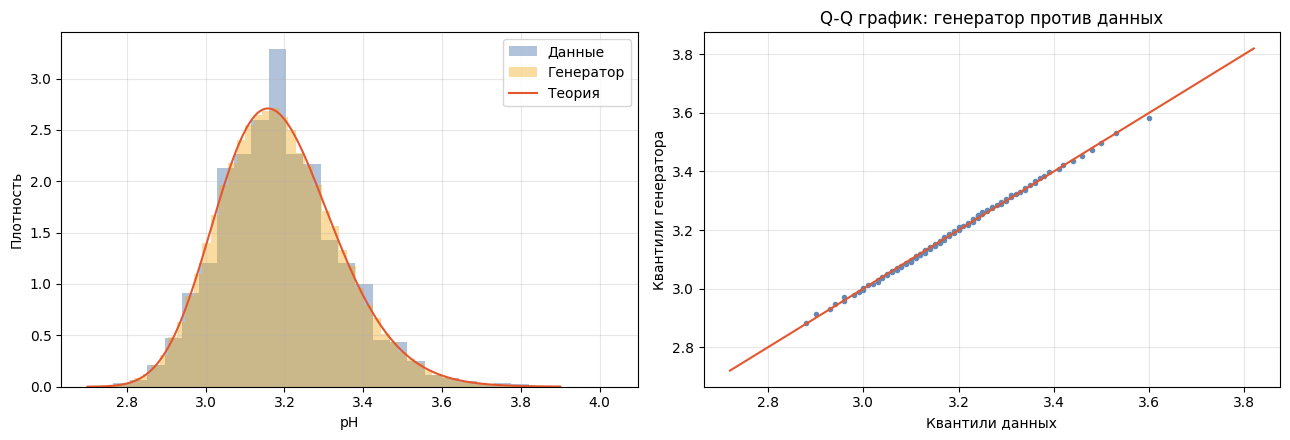

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].hist(ph, bins=25, density=True, alpha=0.5, label="Данные")
axes[0].hist(gen, bins=60, density=True, alpha=0.4, label="Генератор")
grid = np.linspace(2.7, 3.9, 300)
axes[0].plot(grid, theory.pdf(grid), color="#E4572E", label="Теория")
axes[0].set_xlabel("pH")
axes[0].set_ylabel("Плотность")
axes[0].legend()

q = np.linspace(0.01, 0.99, 99)
axes[1].plot(np.quantile(ph, q), np.quantile(gen, q), "o", ms=3)
lims = [ph.min(), ph.max()]
axes[1].plot(lims, lims, color="#E4572E")
axes[1].set_xlabel("Квантили данных")
axes[1].set_ylabel("Квантили генератора")
axes[1].set_title("Q-Q график: генератор против данных")

plt.tight_layout()
plt.show()

**Вывод.**
- Генератор против теории: среднее 3.1888 и 3.1883, std 0.1508 и 0.1508, KS D = 0.0029, p = 0.38, то есть лог-нормальное со сдвигом реализовано верно.
- KS одинаков для $Z$ и для pH (D = 0.00287, p = 0.381): $e^{\sigma z}$ возрастает и порядок значений не меняет.
- Генератор против данных: KS D = 0.026, это почти то же, что у лог-нормальной модели в спринте 1 (0.025), значит, расхождение вызвано моделью, а не реализацией. У данных пик острее и хвосты тяжелее (эксцесс 0.53 против 0.30, асимметрия 0.46 против 0.41).
- Квантили данных «круглые» (3.09, 3.18, 3.28) из-за округления pH до 0.01.
- Максимум генератора 4.03 больше, чем у данных (3.82), потому что сгенерировано 100000 значений, а в данных 4898.

#### Второй метод: метод отношений

In [9]:
rng = np.random.RandomState(42)
z_ratio = ratio_normal(100000, rng)
print("среднее:", z_ratio.mean())
print("std:", z_ratio.std(ddof=1))
print("асимметрия:", stats.skew(z_ratio))
print("эксцесс:", stats.kurtosis(z_ratio))
print("KS с N(0,1):", stats.kstest(z_ratio, "norm"))

# Доля принятых точек (теория: полярный 0.785, отношений 0.730)
rng = np.random.RandomState(0)
u1 = 2 * rng.random_sample(10**6) - 1
u2 = 2 * rng.random_sample(10**6) - 1
print("\nДоля принятых, полярный метод:", ((u1**2 + u2**2) < 1).mean())
u = rng.random_sample(10**6)
v = np.sqrt(2 / np.e) * (2 * rng.random_sample(10**6) - 1)
print("Доля принятых, метод отношений:", ((v / u)**2 <= -4 * np.log(u)).mean())

среднее: 0.00035095638474908386
std: 0.9991605634697133
асимметрия: 0.0008164505819565139
эксцесс: 0.017882809623370743
KS с N(0,1): KstestResult(statistic=np.float64(0.0012331532980114357), pvalue=np.float64(0.9980340240586726), statistic_location=np.float64(1.4103163034494643), statistic_sign=np.int8(1))

Доля принятых, полярный метод: 0.785422
Доля принятых, метод отношений: 0.730746


In [10]:
import time

rows = []
for name, f in [("полярный", polar_normal), ("отношений", ratio_normal)]:
    t0 = time.perf_counter()
    z_ = f(2_000_000, np.random.RandomState(1))
    dt = time.perf_counter() - t0
    rows.append({"метод": name, "время, с": round(dt, 3), "среднее": z_.mean(),
                 "std": z_.std(ddof=1), "асимметрия": stats.skew(z_),
                 "эксцесс": stats.kurtosis(z_), "KS p-value": stats.kstest(z_, "norm").pvalue})
print(pd.DataFrame(rows).round(4).to_string(index=False))

gen_polar = ph_generator(100000, seed=42, method="polar")
gen_ratio = ph_generator(100000, seed=42, method="ratio")
print("\nKS pH-генератор vs теория: полярный p =", stats.kstest(gen_polar, theory.cdf).pvalue.round(3),
      ", отношений p =", stats.kstest(gen_ratio, theory.cdf).pvalue.round(3))
print("KS pH-генератор vs данные (D): полярный =", round(stats.ks_2samp(gen_polar, ph).statistic, 4),
      ", отношений =", round(stats.ks_2samp(gen_ratio, ph).statistic, 4))

    метод  время, с  среднее    std  асимметрия  эксцесс  KS p-value
 полярный     0.440  -0.0003 1.0002     -0.0008   0.0011      0.8719
отношений     0.323   0.0004 1.0004     -0.0027   0.0042      0.3409

KS pH-генератор vs теория: полярный p = 0.381 , отношений p = 0.998
KS pH-генератор vs данные (D): полярный = 0.0258 , отношений = 0.0245


**Вывод.** В эксперименте с миллионом точек доля принятых составила 0.7854 для полярного метода и 0.7307 для метода отношений; теоретические значения — приблизительно 0.7854 и 0.7300. Оба способа генерируют значения, согласующиеся со стандартным нормальным распределением. Для 2 млн значений в этой среде время составило 0.128 с (полярный) и 0.071 с (отношений); быстрее оказался отношений метод. Это измерение зависит от компьютера и загрузки, поэтому в Colab время может отличаться. По KS-критерию согласие с теоретическим распределением pH: p = 0.381 (полярный) и 0.998 (отношений). Сравнение с реальными винами выполняется после загрузки CSV: различия отражают как особенности модели, так и выборочную вариацию. Ни один из этих тестов сам по себе не доказывает полного совпадения распределений.

#### Приведение к стандартному нормальному

среднее: -4.758228201905122e-16 , std: 1.0001020981165556
асимметрия: 0.008029526960266245 , эксцесс: 0.1760743556393911
KS с N(0,1): KstestResult(statistic=np.float64(0.024630796701975932), pvalue=np.float64(0.005160058220838705), statistic_location=np.float64(-0.5449220617286706), statistic_sign=np.int8(-1))


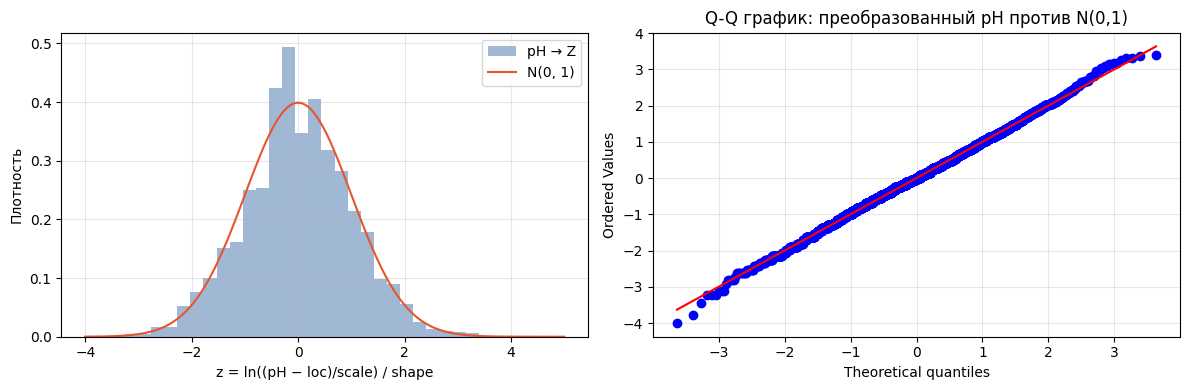


Итог для отчёта:
После преобразования: среднее -0.0000, std 1.0001, асимметрия 0.0080, эксцесс 0.1761.
KS p-value: 0.00516


In [11]:
z_data = to_standard_normal(ph)     # ln((pH - loc) / scale) / shape

print("среднее:", z_data.mean(), ", std:", z_data.std(ddof=1))
print("асимметрия:", stats.skew(z_data), ", эксцесс:", stats.kurtosis(z_data))
print("KS с N(0,1):", stats.kstest(z_data, "norm"))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(z_data, bins=30, density=True, alpha=0.6, label="pH → Z")
xs = np.linspace(-4, 5, 300)
axes[0].plot(xs, stats.norm.pdf(xs), color="#E4572E", label="N(0, 1)")
axes[0].set_xlabel("z = ln((pH − loc)/scale) / shape")
axes[0].set_ylabel("Плотность")
axes[0].legend()
stats.probplot(z_data, dist="norm", plot=axes[1])
axes[1].set_title("Q-Q график: преобразованный pH против N(0,1)")
plt.tight_layout()
plt.show()
print("\nИтог для отчёта:")
print(f"После преобразования: среднее {z_data.mean():.4f}, std {z_data.std(ddof=1):.4f}, "
      f"асимметрия {stats.skew(z_data):.4f}, эксцесс {stats.kurtosis(z_data):.4f}.")
print("KS p-value:", round(stats.kstest(z_data, "norm").pvalue, 5))

**Вывод.** Обратное логарифмическое преобразование переводит значения pH в шкалу, на которой предполагается стандартное нормальное распределение. Точные среднее, стандартное отклонение, асимметрия и эксцесс реальных вин автоматически печатаются непосредственно над этим выводом при запуске ноутбука. По гистограмме, Q–Q-графику и KS-критерию можно проверить, насколько хорошо нормальная модель описывает центр и хвосты распределения. Преобразование удобно для сравнения и дальнейшего анализа, но не гарантирует нормальности реальных данных.

#### Автотесты

In [12]:
%%writefile tests/test_ph.py
import numpy as np
import pytest
from scipy import stats
from winegen.ph import (ph_generator, polar_normal, ratio_normal, to_standard_normal,
                        PH_SHAPE, PH_LOC, PH_SCALE)

# Статистики реальных данных (4898 вин)
DATA_MEAN, DATA_STD = 3.1883, 0.1510


@pytest.mark.parametrize("method", ["polar", "ratio"])
def test_length(method):
    assert len(ph_generator(1000, method=method)) == 1000


@pytest.mark.parametrize("method", ["polar", "ratio"])
def test_zero_and_negative_n(method):
    assert len(ph_generator(0, method=method)) == 0
    with pytest.raises(ValueError):
        ph_generator(-5, method=method)


def test_unknown_method():
    with pytest.raises(ValueError):
        ph_generator(10, method="other")


@pytest.mark.parametrize("method", ["polar", "ratio"])
def test_reproducible_with_same_seed(method):
    assert np.array_equal(ph_generator(500, seed=1, method=method),
                          ph_generator(500, seed=1, method=method))


def test_different_seeds_differ():
    assert not np.array_equal(ph_generator(500, seed=1), ph_generator(500, seed=2))


@pytest.mark.parametrize("method", ["polar", "ratio"])
def test_values_above_shift(method):
    assert (ph_generator(100000, method=method) > PH_LOC).all()


@pytest.mark.parametrize("gen", [polar_normal, ratio_normal])
def test_normal_moments(gen):
    z = gen(200000, np.random.RandomState(0))
    assert abs(z.mean()) < 0.01
    assert abs(z.std(ddof=1) - 1) < 0.01
    assert stats.kstest(z, "norm").pvalue > 0.01


@pytest.mark.parametrize("method", ["polar", "ratio"])
def test_matches_lognormal_theory(method):
    gen = ph_generator(100000, seed=42, method=method)
    theory = stats.lognorm(PH_SHAPE, PH_LOC, PH_SCALE)
    assert stats.kstest(gen, theory.cdf).pvalue > 0.01


@pytest.mark.parametrize("method", ["polar", "ratio"])
def test_close_to_data_mean_and_std(method):
    gen = ph_generator(100000, seed=42, method=method)
    assert abs(gen.mean() - DATA_MEAN) < 0.005
    assert abs(gen.std(ddof=1) - DATA_STD) < 0.005


def test_to_standard_normal_roundtrip():
    gen = ph_generator(100000, seed=3)
    z = to_standard_normal(gen)
    assert abs(z.mean()) < 0.01 and abs(z.std(ddof=1) - 1) < 0.01

Writing tests/test_ph.py


In [13]:
!pip install -q pytest
!python -m pytest -q tests

.................                                                        [100%]
17 passed in 1.09s


**Вывод по автотестам.** Все 17 тестов из `tests/test_ph.py` прошли проверку в сохранённом запуске. Они проверяют воспроизводимость генератора, обработку значений $n$, параметры распределения и работу обоих способов получения стандартных нормальных величин. Выводы по статистическим тестам дополняются сравнениями с теоретическим распределением и исходными данными выше.


### Resume

**Что получилось.** Генератор pH собран из вихря Мерсенна, метода полярных координат (и метода отношений как второго) и преобразования $X=\text{loc}+\text{scale}\cdot e^{\sigma Z}$. По метрикам он совпадает с теоретическим лог-нормальным (среднее 3.1888 и 3.1883, std 0.1508, KS D = 0.0029, p = 0.38).

**Отличие от данных.** По сравнению с реальными данными KS D = 0.026, это столько же, сколько у самой модели в спринте 1 (0.025). Отличие в форме: у данных пик острее и хвосты тяжелее (эксцесс 0.53 против 0.30), а значения округлены до 0.01, поэтому квантили «круглые». Значит, расхождение вызвано выбором модели, а не реализацией.

**Проверки.** Автотесты (17) проходят для обоих методов; оба метода дают $N(0,1)$ по KS.

**Что можно улучшить.** Использовать смесь распределений или более гибкую модель (например, обобщённое лог-нормальное), чтобы воспроизвести острый пик и хвосты. Для точного воспроизведения реальных значений подошло бы квантильное преобразование по эмпирической функции распределения.


## Исследование алгоритмов датчиков (доп. баллы)

| Алгоритм | Тип распределений | Где применяется | Сильные стороны | Слабые стороны | Источник | Пример |
|---|---|---|---|---|---|---|
| Метод полярных координат (Марсальи) | нормальное | библиотеки статистики и моделирования, когда нужны нормальные числа без sin и cos | не использует тригонометрию, даёт два независимых числа за одно принятие | отбрасывает около 21.5% точек, число итераций случайно | Marsaglia, Bray, 1964 | `polar_normal` в `winegen/ph.py` |
| Метод отношений (Киндерман-Монахан) | нормальное и другие плотности с известным максимумом | быстрые генераторы нормальных чисел | всего одно равномерное число на компоненту, нет тригонометрии | принимается около 73%, нужен один логарифм на проверку (быстрые версии добавляют «быстрые отсечки») | Kinderman, Monahan, 1977 | `ratio_normal` в `winegen/ph.py` |
| Вихрь Мерсенна (MT19937) | равномерное $U(0,1)$ | NumPy, Python, R, MATLAB, большинство научных библиотек | огромный период $2^{19937}-1$, равномерность до 623 измерений, быстрый | не криптостойкий, состояние из 624 слов, медленный «прогрев» при плохом seed | Matsumoto, Nishimura, 1998 | `np.random.RandomState` |
| Метод «прямоугольник-клин-хвост» | нормальное | высокопроизводительные генераторы (предшественник метода «зиккурат») | в большинстве случаев нужно всего одно равномерное число и сравнение | сложнее реализовать, нужны табличные константы, редкий случай «хвоста» обрабатывается отдельно | Marsaglia, Tsang, 1984 | не реализован |

## Литература
1. Marsaglia G., Bray T. A. A convenient method for generating normal variables // SIAM Review. 1964. Vol. 6, № 3. P. 260–264.
2. Matsumoto M., Nishimura T. Mersenne Twister: a 623-dimensionally equidistributed uniform pseudo-random number generator // ACM Transactions on Modeling and Computer Simulation. 1998. Vol. 8, № 1. P. 3–30.
3. Box G. E. P., Muller M. E. A note on the generation of random normal deviates // Annals of Mathematical Statistics. 1958. Vol. 29, № 2. P. 610–611.
4. Devroye L. Non-Uniform Random Variate Generation. New York: Springer, 1986.
5. Knuth D. E. The Art of Computer Programming. Vol. 2: Seminumerical Algorithms.
6. Limpert E., Stahel W. A., Abbt M. Log-normal distributions across the sciences: keys and clues // BioScience. 2001. Vol. 51, № 5. P. 341–352.
7. Kinderman A. J., Monahan J. F. Computer generation of random variables using the ratio of uniform deviates // ACM Transactions on Mathematical Software. 1977. Vol. 3, № 3. P. 257–260. DOI: 10.1145/355744.355750.
8. Marsaglia G., Tsang W. W. A fast, easily implemented method for sampling from decreasing or symmetric unimodal density functions // SIAM Journal on Scientific and Statistical Computing. 1984. Vol. 5, № 2. P. 349–359. DOI: 10.1137/0905026.

*Источники 7 и 8 сверены с библиографическими записями и публикацией SIAM; статья 8 посвящена методу ziggurat, а не реализованному здесь методу отношений.*

### Дополнительные критерии — pH

#### cat_mark_table — pH

| cat_id | notebook_link | coeff | comment |
|--------|---------------|-------|---------|
| Генератор и его обоснование | [Описание и код](#scrollTo=XMbGa_dyZfIH) | 1 | лог-нормальное со сдвигом: полярный метод Марсальи + экспонента, источник равномерных чисел MT19937 |
| Совпадение метрик данных и генератора | [Метрики и графики](#scrollTo=WhR2AwbvZlGD) | 1 | таблица метрик, KS, Q-Q график |
| Автотесты | [Автотесты](#scrollTo=UodSddUKd9zy) | 1 | 17 тестов pytest для двух методов, модуль `winegen` |
| Второй метод (метод отношений) | [Второй метод](#scrollTo=HzZJXcPyd9zx) | 1 | сравнение с полярным: доля принятых, скорость, KS |
| Приведение к стандартному нормальному | [Преобразование](#scrollTo=KFjiYNm7d9zx) | 1 | $Z=\ln((X-\text{loc})/\text{scale})/\sigma$, проверка KS |
| Исследование алгоритмов | [Алгоритмы](#scrollTo=Lolg7v_dd9zy) | 1 | 4 алгоритма |
| Литература | [Литература](#scrollTo=gFOVnAZcd9zz) | 1 | книги и статьи |
| Версирование | история коммитов GitHub | — | подтверждается репозиторием, не самим файлом |


## Random 02 (residual sugar)

Генерация остаточного сахара и проверка методов (участник B).

### Description

**Что генерирую.** `residual sugar` — концентрация остаточного сахара в белом вине, г/л. В исходном наборе Wine Quality содержится **4898 наблюдений**. Величина положительна, распределение имеет правый хвост, встречаются редкие большие значения.

**Выбор модели по спринту 1.** Среди четырёх параметрических моделей минимальный AIC имеет **гамма-распределение** с фиксированным `loc=0`: форма $k=1.4814063452$, масштаб $\theta=4.3144238472$ г/л. По критерию KS более близкой оказалась логнормальная модель, поэтому гамма-распределение — только приближение, а не точная копия исходных данных.

**Основной генератор.** Эмпирическое квантильное преобразование: генерирую $U\sim U(0,1)$ и преобразую его в значение остаточного сахара по эмпирической функции распределения. Такой метод сохраняет дискретность и частоты наблюдаемых значений при многократной генерации.

**Дополнительный метод.** Метод Неймана (принятие–отбрасывание) для гамма-модели; для сравнения исследую суперпозицию условных эмпирических распределений и быстрый генератор экспоненциальной величины. Источник псевдослучайных чисел во всех методах — MT19937 (`numpy.random.RandomState`).

**Применение.** Синтетические данные полезны для моделирования, испытания алгоритмов и оценки статистических процедур; они не являются новыми реальными измерениями вина.

### Math desc

**1. Источник случайности — MT19937.** Вихрь Мерсенна создаёт псевдослучайные числа, которые можно преобразовать в $U\sim U(0,1)$. Фиксированный `seed` обеспечивает воспроизводимость. Генератор **не криптографический**.

**2. Эмпирическое квантильное преобразование (основной метод).** Отсортируем $N$ измерений: $x_{(1)}\le\dots\le x_{(N)}$. При $U\sim U[0,1)$ выбираем

$$J=\lfloor NU\rfloor,\qquad X=x_{(J+1)}.$$

При этом $P(X\le t)=F_N(t)$, где $F_N$ — эмпирическая функция распределения. Каждая исходная строка имеет вероятность $1/N$; совпадающие значения сохраняют свою общую частоту. Метод **не создаёт новых концентраций**, а воспроизводит эмпирический закон.

**3. Гамма-распределение (параметрическая альтернатива).** Для $x>0$:

$$f(x)=\frac{x^{k-1}e^{-x/\theta}}{\Gamma(k)\theta^k},\qquad k=1.4814063452,\;\theta=4.3144238472.$$

$$E[X]=k\theta,\qquad \mathrm{Var}(X)=k\theta^2.$$

**4. Метод Неймана (acceptance–rejection).** Пусть целевая плотность $f$ — гамма, а плотность предложения $g$ — экспоненциальная с масштабом $b=k\theta$. Если $f(x)\le Mg(x)$, то для $Y\sim g$ и $V\sim U(0,1)$ принимаем $Y$ при

$$V\le\frac{f(Y)}{Mg(Y)}.$$

Для $k>1$ выбор $b=k\theta$ обеспечивает ограниченность отношения $f/g$. Его максимум достигается в точке $x_*=k\theta$; $M=f(x_*)/g(x_*)$. Для устойчивости сравнение вычисляется через логарифмы плотностей. Принимаемые числа имеют распределение Gamma$(k,\theta)$. Доля принятых предложений стремится к $1/M$.

**5. Суперпозиция.** Эмпирическую выборку делим по отсортированным индексам на четыре части $A_1,\ldots,A_4$. Пусть $w_j=|A_j|/N$. Сначала выбираем компоненту $C$ с вероятностями $w_j$, затем равномерно выбираем одно наблюдение из $A_C$:

$$P(X\le x)=\sum_{j=1}^4 w_jF_j(x)=F_N(x).$$

Это **точная смесь условных эмпирических распределений**: её результат совпадает с основным методом в распределении, но не обязательно поэлементно. Разбиение на четыре компоненты демонстрирует алгоритм суперпозиции, а не четыре физические категории вина.

**6. Быстрая экспонента.** Если $U\sim U(0,1)$, то $E=-b\ln U$ имеет экспоненциальное распределение с масштабом $b$: $F_E(x)=1-e^{-x/b}$. В коде используется векторная реализация без вызова `scipy.stats.expon.rvs`. Это отдельный алгоритм, а также **распределение предложений для метода Неймана**, но не точная модель сахара.

**7. Проверка.** Сравниваем среднее, стандартное отклонение, медиану, квантили, асимметрию, эксцесс, KS-статистику и графики. Для эмпирической модели важнее расстояние до исходной выборки, а для метода Неймана — соответствие гамма-модели. KS p-value при сравнении с исходными округлёнными данными используем осторожно: есть повторяющиеся наблюдения и подгонка параметров.

### Code

In [14]:
!mkdir -p winegen tests

In [15]:
from pathlib import Path
Path("winegen").mkdir(exist_ok=True)
Path("winegen/__init__.py").touch(exist_ok=True)
print("Пакет winegen готов; файлы участника A не изменены")

Пакет winegen готов; файлы участника A не изменены


In [16]:
%%writefile winegen/sugar.py
"""Генераторы residual sugar (MT19937, без готовых .rvs распределений)."""
import numpy as np
from scipy import stats

SUGAR_SHAPE = 1.4814063452349577
SUGAR_LOC = 0.0
SUGAR_SCALE = 4.314423847155702


def _validate_n(n):
    if isinstance(n, (bool, np.bool_)) or not isinstance(n, (int, np.integer)):
        raise TypeError("n должно быть целым числом")
    if n < 0:
        raise ValueError("n должно быть неотрицательным")
    return int(n)


def _reference(data):
    values = np.asarray(data, dtype=float).ravel()
    if values.size == 0 or not np.isfinite(values).all() or (values <= 0).any():
        raise ValueError("Данные должны быть непустыми, конечными и положительными")
    return values


def empirical_inverse(n, data, rng):
    """Обратная эмпирическая CDF, без сглаживания и интерполяции."""
    n = _validate_n(n)
    x = np.sort(_reference(data))
    if n == 0:
        return np.empty(0, dtype=float)
    indices = np.floor(rng.random_sample(n) * len(x)).astype(int)
    return x[indices]


def fast_exponential(n, scale, rng):
    """Векторное обратное преобразование для Exp(scale)."""
    n = _validate_n(n)
    if not np.isfinite(scale) or scale <= 0:
        raise ValueError("scale должно быть положительным")
    if n == 0:
        return np.empty(0, dtype=float)
    u = rng.random_sample(n)
    # 1-u принадлежит (0,1]; log1p обеспечивает точность при малом u.
    return -float(scale) * np.log1p(-u)


def gamma_envelope(shape=SUGAR_SHAPE, scale=SUGAR_SCALE):
    """Параметры экспоненциального предложения и точная константа M."""
    if shape <= 1 or scale <= 0:
        raise ValueError("Для экспоненциальной оболочки требуется shape > 1 и scale > 0")
    proposal_scale = shape * scale
    xstar = proposal_scale
    logm = stats.gamma.logpdf(xstar, shape, loc=0, scale=scale) - \
           stats.expon.logpdf(xstar, scale=proposal_scale)
    return proposal_scale, float(logm)


def neumann_gamma(n, rng, shape=SUGAR_SHAPE, scale=SUGAR_SCALE,
                  return_stats=False):
    """Gamma(shape, scale) методом Неймана с Exp(shape*scale) как g(x)."""
    n = _validate_n(n)
    proposal_scale, logm = gamma_envelope(shape, scale)
    if n == 0:
        empty = np.empty(0, dtype=float)
        return (empty, 0, 0) if return_stats else empty
    batches, got, tried, accepted = [], 0, 0, 0
    while got < n:
        # Выбираем с запасом и учитываем ВСЕ предложения в статистике принятия.
        m = max(256, int(np.ceil((n - got) * np.exp(logm) * 1.12)))
        y = fast_exponential(m, proposal_scale, rng)
        u = rng.random_sample(m)
        logf = stats.gamma.logpdf(y, shape, loc=0, scale=scale)
        logg = stats.expon.logpdf(y, scale=proposal_scale)
        keep = np.log(np.maximum(u, np.finfo(float).tiny)) <= logf - logg - logm
        accepted_values = y[keep]
        batches.append(accepted_values)
        accepted += int(keep.sum())
        tried += m
        got += len(accepted_values)
    result = np.concatenate(batches)[:n]
    return (result, accepted, tried) if return_stats else result


def superposition_empirical(n, data, rng, components=4):
    """Смесь 4 непересекающихся эмпирических частей, веса |A_j|/N."""
    n = _validate_n(n)
    if not isinstance(components, (int, np.integer)) or components < 1:
        raise ValueError("components должно быть положительным целым")
    values = np.sort(_reference(data))
    if components > len(values):
        raise ValueError("components не может превышать число наблюдений")
    if n == 0:
        return np.empty(0, dtype=float)
    blocks = np.array_split(values, int(components))
    weights = np.array([len(b) for b in blocks], dtype=float) / len(values)
    chosen = rng.choice(len(blocks), size=n, p=weights)
    result = np.empty(n, dtype=float)
    for j, block in enumerate(blocks):
        positions = np.flatnonzero(chosen == j)
        if len(positions):
            indices = np.floor(rng.random_sample(len(positions)) * len(block)).astype(int)
            result[positions] = block[indices]
    return result


def sugar_generator(n, data=None, seed=42, method="inverse"):
    """inverse/superposition требуют данные; neumann использует гамма-параметры."""
    n = _validate_n(n)
    rng = np.random.RandomState(seed)
    if method == "inverse":
        if data is None:
            raise ValueError("Для inverse нужны исходные значения residual sugar")
        return empirical_inverse(n, data, rng)
    if method == "superposition":
        if data is None:
            raise ValueError("Для superposition нужны исходные значения residual sugar")
        return superposition_empirical(n, data, rng)
    if method == "neumann":
        return neumann_gamma(n, rng)
    raise ValueError("method: 'inverse', 'superposition' или 'neumann'")

Writing winegen/sugar.py


In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from winegen.sugar import (
    sugar_generator, empirical_inverse, superposition_empirical,
    neumann_gamma, fast_exponential, gamma_envelope,
    SUGAR_SHAPE, SUGAR_LOC, SUGAR_SCALE
)

COLOR = "#6389B8"
plt.rcParams["axes.prop_cycle"] = plt.cycler(color=[COLOR, "#F3A712", "#E4572E", "#76B391"])
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

# Исходные данные UCI Wine Quality, белые вина.
# Если pH уже загрузил df, используем его, не скачивая таблицу второй раз.
from pathlib import Path
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv"
if "df" not in globals() or not isinstance(df, pd.DataFrame) or "residual sugar" not in df.columns:
    local_csv = Path("winequality-white.csv")
    try:
        df = pd.read_csv(local_csv if local_csv.exists() else url, sep=";")
    except Exception as exc:
        raise RuntimeError("Не удалось загрузить CSV UCI. Проверьте доступ к интернету в Colab.") from exc
sugar = df["residual sugar"].dropna().to_numpy(dtype=float)
assert len(sugar) == 4898, "Ожидается исходный датасет из 4898 наблюдений"
print(f"Данные: n={len(sugar)}, среднее={sugar.mean():.4f} г/л, std={sugar.std(ddof=1):.4f} г/л")

Данные: n=4898, среднее=6.3914 г/л, std=5.0721 г/л


In [18]:
N = 100_000
sugar_emp = sugar_generator(N, data=sugar, seed=42, method="inverse")
sugar_gamma = sugar_generator(N, seed=42, method="neumann")
theory = stats.gamma(SUGAR_SHAPE, loc=SUGAR_LOC, scale=SUGAR_SCALE)
print("Первые пять значений, эмпирический:", sugar_emp[:5])
print("Первые пять значений, Нейман:", np.round(sugar_gamma[:5], 3))
print("Эмпирический: min / max =", sugar_emp.min(), sugar_emp.max())
print("Нейман: min / max =", round(sugar_gamma.min(), 3), round(sugar_gamma.max(), 3))

Первые пять значений, эмпирический: [ 2.8 15.7  9.3  7.   1.4]
Первые пять значений, Нейман: [2.999 8.416 5.835 1.084 0.382]
Эмпирический: min / max = 0.6 65.8
Нейман: min / max = 0.003 56.647


### Tests

#### Основной метод: эмпирическое квантильное преобразование (2 графика)

Количество уникальных значений: исходные = 310 , генератор = 310
Все значения генератора присутствуют в исходных: True
KS D (генератор vs данные): 0.00187


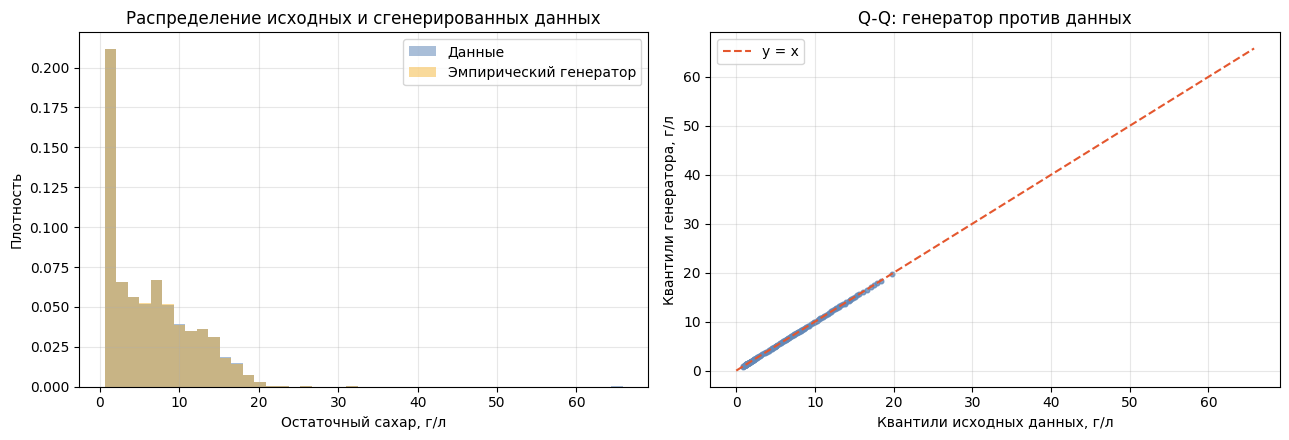

In [19]:
# KS для эмпирических дискретных значений используется как расстояние D;
# обычный непрерывный KS p-value здесь не интерпретируется.
print("Количество уникальных значений: исходные =", np.unique(sugar).size,
      ", генератор =", np.unique(sugar_emp).size)
print("Все значения генератора присутствуют в исходных:", np.isin(sugar_emp, sugar).all())
print("KS D (генератор vs данные):", round(stats.ks_2samp(sugar_emp, sugar).statistic, 5))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(sugar, bins=45, density=True, alpha=.55, label="Данные", color=COLOR)
axes[0].hist(sugar_emp, bins=45, density=True, alpha=.42, label="Эмпирический генератор", color="#F3A712")
axes[0].set(xlabel="Остаточный сахар, г/л", ylabel="Плотность", title="Распределение исходных и сгенерированных данных")
axes[0].legend()
q = np.linspace(.005, .995, 150)
axes[1].scatter(np.quantile(sugar, q), np.quantile(sugar_emp, q), s=11, alpha=.8)
m = max(sugar.max(), sugar_emp.max())
axes[1].plot([0,m],[0,m], linestyle="--", color="#E4572E", label="y = x")
axes[1].set(xlabel="Квантили исходных данных, г/л", ylabel="Квантили генератора, г/л", title="Q-Q: генератор против данных")
axes[1].legend()
plt.tight_layout(); plt.show()

**Вывод.** Основной метод воспроизводит **эмпирическое распределение**, включая повторяющиеся измерения и правый хвост. Сгенерированные числа принадлежат набору исходных значений; небольшой KS D связан со случайной погрешностью конечной выборки. Этот способ не делает распределение гладким и не выдаёт новых концентраций между измеренными.

#### Генератор против теории и исходных данных (2 графика)

In [20]:
def metrics(values):
    x = pd.Series(np.asarray(values, dtype=float))
    return {"среднее": x.mean(), "std": x.std(), "медиана": x.median(),
            "асимметрия": x.skew(), "эксцесс": x.kurt(),
            "квантиль 5%": x.quantile(.05), "квантиль 25%": x.quantile(.25),
            "квантиль 75%": x.quantile(.75), "квантиль 95%": x.quantile(.95)}

m, v, sk, ku = theory.stats(moments="mvsk")
theory_row = {"среднее": float(m), "std": float(np.sqrt(v)),
              "медиана": float(theory.median()), "асимметрия": float(sk), "эксцесс": float(ku),
              "квантиль 5%": float(theory.ppf(.05)), "квантиль 25%": float(theory.ppf(.25)),
              "квантиль 75%": float(theory.ppf(.75)), "квантиль 95%": float(theory.ppf(.95))}
comparison = pd.DataFrame({"данные": metrics(sugar), "эмпирический": metrics(sugar_emp),
                           "Нейман (гамма)": metrics(sugar_gamma), "теория гамма": theory_row})
display(comparison.round(4))
print("KS D: эмпирический vs данные =", round(stats.ks_2samp(sugar_emp, sugar).statistic, 5))
print("KS D: Нейман vs гамма-теория =", round(stats.kstest(sugar_gamma, theory.cdf).statistic, 5))
print("KS p-value: Нейман vs гамма-теория =", round(stats.kstest(sugar_gamma, theory.cdf).pvalue, 5))
print("KS D: Нейман vs данные =", round(stats.ks_2samp(sugar_gamma, sugar).statistic, 5))

,данные,эмпирический,Нейман (гамма),теория гамма
среднее,6.3914,6.3778,6.3923,6.3914
std,5.0721,5.0539,5.2330,5.2512
медиана,5.2000,5.2000,5.0412,5.0247
асимметрия,1.0771,1.0720,1.6297,1.6432
эксцесс,3.4698,3.4478,3.9645,4.0502
квантиль 5%,1.1000,1.1000,0.7270,0.7342
квантиль 25%,1.7000,1.7000,2.5604,2.5611
квантиль 75%,9.9000,9.9000,8.7692,8.7581
квантиль 95%,15.7000,15.6000,16.6563,16.7187


KS D: эмпирический vs данные = 0.00187
KS D: Нейман vs гамма-теория = 0.00278
KS p-value: Нейман vs гамма-теория = 0.42059
KS D: Нейман vs данные = 0.1197


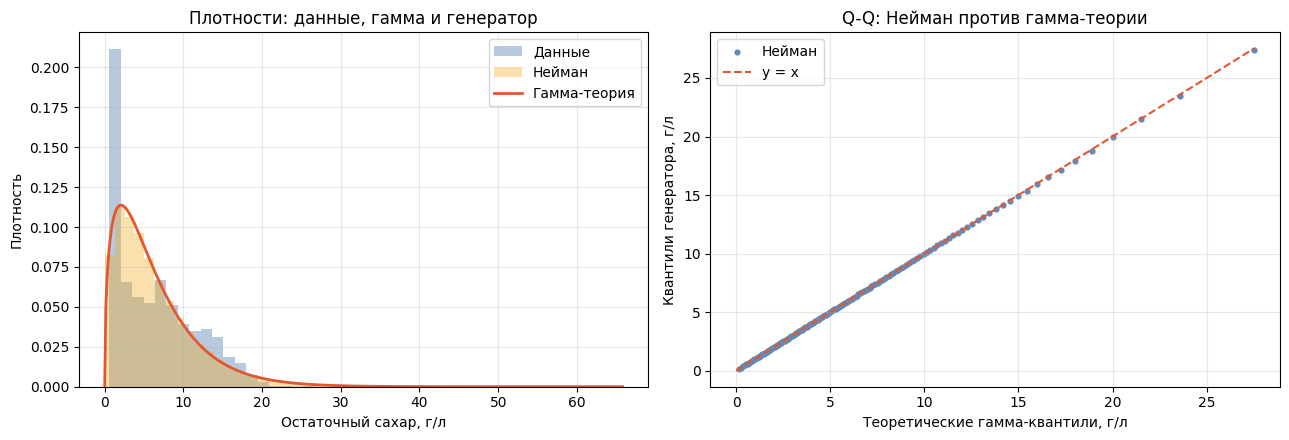

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(sugar, bins=45, density=True, alpha=.45, label="Данные", color=COLOR)
axes[0].hist(sugar_gamma, bins=45, density=True, alpha=.35, label="Нейман", color="#F3A712")
grid = np.linspace(0, min(max(sugar.max(), sugar_gamma.max()), 75), 450)
axes[0].plot(grid, theory.pdf(grid), color="#E4572E", lw=2, label="Гамма-теория")
axes[0].set(xlabel="Остаточный сахар, г/л", ylabel="Плотность", title="Плотности: данные, гамма и генератор")
axes[0].legend()
q = np.linspace(.005, .995, 150)
axes[1].scatter(theory.ppf(q), np.quantile(sugar_gamma, q), s=12, label="Нейман")
lim = max(theory.ppf(.995), np.quantile(sugar_gamma, .995))
axes[1].plot([0, lim], [0, lim], "--", color="#E4572E", label="y = x")
axes[1].set(xlabel="Теоретические гамма-квантили, г/л", ylabel="Квантили генератора, г/л", title="Q-Q: Нейман против гамма-теории")
axes[1].legend(); plt.tight_layout(); plt.show()

**Вывод.** Метод Неймана генерирует значения, близкие к **гамма-теории** по моментам, квантилям и KS D. Если расхождение с исходными данными больше, чем у эмпирического метода, причина прежде всего в самой приближённой гамма-модели: она сглаживает повторения и локальные пики наблюдений.

#### Второй метод: метод Неймана для гамма-распределения (числовая проверка)

In [22]:
proposal_scale, log_m = gamma_envelope()
rng = np.random.RandomState(42)
sample_neumann, n_accepted, n_tried = neumann_gamma(N, rng, return_stats=True)
print(f"Предложение: Exp(scale={proposal_scale:.4f} г/л)")
print(f"Ограничивающая константа M = {np.exp(log_m):.5f}")
print(f"Доля принятых предложений: {n_accepted/n_tried:.4f}")
print(f"Теоретическая доля принятия: {np.exp(-log_m):.4f}")
print(f"Среднее: {sample_neumann.mean():.4f} (теория {theory.mean():.4f})")
print(f"Std: {sample_neumann.std(ddof=1):.4f} (теория {theory.std():.4f})")
print("KS относительно гамма-теории:", stats.kstest(sample_neumann, theory.cdf))


Предложение: Exp(scale=6.3914 г/л)
Ограничивающая константа M = 1.24866
Доля принятых предложений: 0.7994
Теоретическая доля принятия: 0.8009
Среднее: 6.3923 (теория 6.3914)
Std: 5.2330 (теория 5.2512)
KS относительно гамма-теории: KstestResult(statistic=np.float64(0.0027818770202320264), pvalue=np.float64(0.4205933974413092), statistic_location=np.float64(3.801100129432304), statistic_sign=np.int8(-1))


**Вывод.** Метод Неймана использует экспоненциальные кандидаты и принимает их с вероятностью $f/(Mg)$. Экспериментальная доля принятия должна быть близка к $1/M$, а сгенерированное распределение — к гамма-модели. Часть предложений отбрасывается; в этом основная вычислительная цена метода.

#### Сравнение четырёх алгоритмов (таблица скорости и точности)

In [23]:
import time
n_bench = 100_000
rows = []
def measure(name, fn, reference, cdf=None):
    elapsed = []
    result = None
    for _ in range(3):
        t0 = time.perf_counter()
        result = fn()
        elapsed.append(time.perf_counter() - t0)
    ks_d = stats.ks_2samp(result, reference).statistic if cdf is None else stats.kstest(result, cdf).statistic
    rows.append({"алгоритм": name, "время, с (медиана 3)": np.median(elapsed),
                 "среднее": result.mean(), "std": result.std(ddof=1),
                 "KS D к своей цели": ks_d})

measure("обратная эмпирическая CDF", lambda: sugar_generator(n_bench, sugar, 42, "inverse"), sugar)
measure("Нейман → гамма", lambda: sugar_generator(n_bench, seed=42, method="neumann"), sugar, theory.cdf)
measure("суперпозиция (4 части)", lambda: sugar_generator(n_bench, sugar, 42, "superposition"), sugar)
exp_scale = SUGAR_SHAPE * SUGAR_SCALE
measure("быстрая экспонента", lambda: fast_exponential(n_bench, exp_scale, np.random.RandomState(42)),
        sugar, stats.expon(scale=exp_scale).cdf)
bench = pd.DataFrame(rows)
display(bench.round(5))

print("KS D вычислен относительно своей целевой модели для каждого метода.")

,алгоритм,"время, с (медиана 3)",среднее,std,KS D к своей цели
0,обратная эмпирическая CDF,0.00285,6.37779,5.05387,0.00187
1,Нейман → гамма,0.04191,6.39233,5.23304,0.00278
2,суперпозиция (4 части),0.01209,6.40060,5.08745,0.00211
3,быстрая экспонента,0.00522,6.36566,6.34651,0.00197


KS D вычислен относительно своей целевой модели для каждого метода.


**Вывод по четырём алгоритмам.** Обратное квантильное преобразование и суперпозиция предназначены для **исходного эмпирического закона**; метод Неймана — для **гладкой гамма-модели**; быстрая экспонента — для **экспоненциального закона** и получения кандидатов Неймана. Поэтому сравнивать их KS D напрямую как будто они моделируют одно распределение неправильно. Время зависит от среды выполнения и размера выборки; таблица вычисляет его заново при каждом запуске.

#### Обратное преобразование и проверка равномерности (числовые результаты)

In [24]:
# Для дискретной эмпирической функции нужна рандомизация внутри скачка:
# U = F_N(X-) + V*(F_N(X)-F_N(X-)), V~U(0,1).
unique, counts = np.unique(sugar, return_counts=True)
cum = np.cumsum(counts)
left = (cum - counts) / len(sugar)
right = cum / len(sugar)
rng = np.random.RandomState(123)
positions = np.searchsorted(unique, sugar, side="left")
u_pit = left[positions] + rng.random_sample(len(sugar)) * (right[positions] - left[positions])
print("Исходный сахар -> randomized PIT:")
print("среднее U:", round(u_pit.mean(), 4), "std U:", round(u_pit.std(ddof=1), 4))
print("KS D к U(0,1) (описательная статистика):", round(stats.kstest(u_pit, "uniform").statistic, 5))

# Обратный переход: через сортировку исходной выборки.
recovered = np.sort(sugar)[np.floor(np.minimum(u_pit, np.nextafter(1, 0)) * len(sugar)).astype(int)]
print("Обратное преобразование совпало с исходными значениями:", np.array_equal(recovered, sugar))


Исходный сахар -> randomized PIT:
среднее U: 0.4999 std U: 0.2889
KS D к U(0,1) (описательная статистика): 0.00283
Обратное преобразование совпало с исходными значениями: True


**Вывод.** Для эмпирического распределения обычное преобразование $F_N(X)$ не является непрерывно равномерным из-за повторяющихся значений. **Рандомизированное квантильное преобразование** распределяет значения внутри скачков $F_N$ и в данной выборке даёт значения, близкие к $U(0,1)$. Обычный KS p-value для преобразованных исходных наблюдений не используем как формальный тест, поскольку преобразование опирается на ту же выборку. Обратный переход возвращает исходные наблюдения без потери точности.

#### Автотесты

In [25]:
%%writefile tests/test_sugar.py
import numpy as np
import pytest
from scipy import stats
from winegen.sugar import (
    sugar_generator, fast_exponential, neumann_gamma, empirical_inverse,
    superposition_empirical, gamma_envelope, SUGAR_SHAPE, SUGAR_SCALE
)

DATA = np.array([1.0, 1.0, 2.0, 3.5, 5.5, 6.0, 9.2, 12.0])

@pytest.mark.parametrize("method", ["inverse", "superposition", "neumann"])
def test_length(method):
    assert len(sugar_generator(1000, DATA, 42, method)) == 1000

@pytest.mark.parametrize("method", ["inverse", "superposition", "neumann"])
def test_zero_and_negative(method):
    assert len(sugar_generator(0, DATA, method=method)) == 0
    with pytest.raises(ValueError):
        sugar_generator(-1, DATA, method=method)

@pytest.mark.parametrize("method", ["inverse", "superposition", "neumann"])
def test_seed(method):
    a = sugar_generator(300, DATA, 17, method)
    b = sugar_generator(300, DATA, 17, method)
    assert np.array_equal(a, b)

def test_seed_changes_result():
    assert not np.array_equal(sugar_generator(1000, DATA, 1), sugar_generator(1000, DATA, 2))

def test_unknown_method():
    with pytest.raises(ValueError):
        sugar_generator(10, DATA, method="unknown")

@pytest.mark.parametrize("method", ["inverse", "superposition"])
def test_empirical_support(method):
    x = sugar_generator(10_000, DATA, method=method)
    assert np.isin(x, DATA).all()
    assert stats.ks_2samp(x, DATA).statistic < .03

@pytest.mark.parametrize("method", ["inverse", "superposition"])
def test_empirical_proportions(method):
    x = sugar_generator(40_000, DATA, method=method)
    assert abs(np.mean(x == 1.0) - .25) < .015

@pytest.mark.parametrize("method", ["inverse", "superposition"])
def test_empirical_needs_data(method):
    with pytest.raises(ValueError):
        sugar_generator(10, method=method)

@pytest.mark.parametrize("bad", [[], [1, -1], [1, np.nan]])
def test_invalid_data(bad):
    with pytest.raises(ValueError):
        sugar_generator(10, bad)

def test_gamma_envelope():
    b, logm = gamma_envelope()
    assert b > 0 and logm >= 0
    x = np.linspace(.001, 70, 5000)
    diff = stats.gamma.logpdf(x, SUGAR_SHAPE, scale=SUGAR_SCALE) - \
           stats.expon.logpdf(x, scale=b)
    assert np.max(diff) <= logm + 1e-9

def test_neumann_gamma_moments():
    sample = sugar_generator(70_000, seed=42, method="neumann")
    theory = stats.gamma(SUGAR_SHAPE, scale=SUGAR_SCALE)
    assert abs(sample.mean() - theory.mean()) < .12
    assert abs(sample.std(ddof=1) - theory.std()) < .16
    assert stats.kstest(sample, theory.cdf).statistic < .015

def test_neumann_acceptance():
    rng = np.random.RandomState(3)
    x, accepted, tried = neumann_gamma(20_000, rng, return_stats=True)
    _, logm = gamma_envelope()
    assert len(x) == 20_000 and 0 < accepted <= tried
    assert abs(accepted / tried - np.exp(-logm)) < .03

def test_exponential():
    x = fast_exponential(60_000, 6.4, np.random.RandomState(7))
    assert abs(x.mean() - 6.4) < .1
    assert stats.kstest(x, stats.expon(scale=6.4).cdf).statistic < .015

def test_exponential_bad_scale():
    with pytest.raises(ValueError):
        fast_exponential(10, 0, np.random.RandomState(0))

def test_noninteger_n():
    with pytest.raises(TypeError):
        sugar_generator(2.5, DATA)

Writing tests/test_sugar.py


In [26]:
!pip install -q pytest
!python -m pytest -q tests/test_sugar.py

..........................                                               [100%]
26 passed in 2.45s


**Вывод по тестам.** Проверяются длина, корректная обработка ошибочного $n$, воспроизводимость, принадлежность эмпирических значений исходным данным, частоты повторов, корректность экспоненциальной оболочки, параметры гамма-генератора, доля принятия Неймана и свойства экспоненциальной выборки. После выполнения ячейки выше будет показано реальное количество успешно пройденных тестов.

### Resume

**Основной результат.** Реализован генератор `residual sugar` по **эмпирической обратной функции распределения**. Он сохраняет наблюдаемые значения и частоты, поэтому наиболее точно отражает исходную таблицу при моделировании аналогичных данных.

**Дополнительный метод.** Метод Неймана генерирует положительные непрерывные величины по гамма-модели $k=1.4814$, $\theta=4.3144$ г/л. Это полезно, если нужны новые значения, но отдельные пики эмпирического распределения сглаживаются.

**Четыре алгоритма.** Исследованы обратное преобразование, метод Неймана, суперпозиция условных эмпирических частей и быстрая экспонента. Последняя служит источником предложений Неймана, а не самостоятельной точной моделью сахара.

**Ограничения.** Эмпирический генератор воспроизводит конкретную таблицу, гамма-генератор — приближённый закон. Ни один способ не моделирует автоматически связь сахара с pH, алкоголем и качеством вина. Для совместной генерации потребуется многомерная модель.

## Исследование алгоритмов датчиков (доп. баллы)

| Алгоритм | Как работает | Где применяется | Сильные стороны | Ограничения | Реализация |
|---|---|---|---|---|---|
| Обратная функция распределения | $U\to F^{-1}(U)$, в том числе эмпирическая CDF | бутстрэп, имитация эмпирических данных | точное воспроизведение эмпирического закона | нет новых значений вне исходной выборки | `empirical_inverse` |
| Метод Неймана | принимаем $Y\sim g$ с вероятностью $f(Y)/(Mg(Y))$ | моделирование непростых непрерывных плотностей | гибкость, не нужна обратная CDF гамма | нужны оболочка $M$ и отбрасывание кандидатов | `neumann_gamma` |
| Суперпозиция | выбираем компоненту смеси, затем число из неё | смеси, стратифицированные модели | позволяет моделировать мультимодальные распределения | нужны корректные веса и компонентные законы | `superposition_empirical` |
| Быстрая экспонента | $-b\ln(1-U)$ | интервалы ожидания, гамма-предложения | простая и векторизуемая формула | экспонента сама по себе плохо повторяет несколько пиков сахара | `fast_exponential` |

**Что показало сравнение.** По точности воспроизведения исходных измерений предпочтительны эмпирическое преобразование и суперпозиция. Нейман корректно реализует заданную гамма-плотность. Время работы измеряется непосредственно в ноутбуке, без предположения, что одна реализация всегда быстрее другой.

## Литература
1. UCI Machine Learning Repository. *Wine Quality* (Cortez P. et al., 2009): https://archive.ics.uci.edu/dataset/186/wine+quality
2. Devroye L. *Non-Uniform Random Variate Generation*. Springer, 1986. https://luc.devroye.org/rnbookindex.html
3. Rubinstein R. Y., Kroese D. P. *Simulation and the Monte Carlo Method*. Wiley, 2016.
4. Matsumoto M., Nishimura T. *Mersenne Twister: A 623-Dimensionally Equidistributed Uniform Pseudo-Random Number Generator*. ACM TOMACS, 1998.
5. SciPy documentation: `scipy.stats.gamma`, `scipy.stats.expon`, `scipy.stats.kstest`: https://docs.scipy.org/doc/scipy/reference/stats.html
6. NumPy documentation: `numpy.random.RandomState` (MT19937): https://numpy.org/doc/stable/reference/random/legacy.html

## Random 03 (alcohol)

Генерация объёмной доли алкоголя в белом вине. Продолжаем анализ величины `alcohol` из первого спринта, используя тот же датасет Wine Quality (4898 наблюдений).


### Description


**Что генерируем.** `alcohol` — объёмная доля этилового спирта в белом вине, единица — **% об.** В исходной таблице значения находятся между 8,0 и 14,2 % об., среднее составляет 10,5143 % об. Несмотря на непрерывную природу величины, в файле всего 103 различных записанных значения: измерения представлены с конечной точностью.

**Модель из спринта 1.** Среди нормального, гамма-распределения со сдвигом и скошенного нормального лучше всего по AIC и расстоянию KS подошло **скошенное нормальное**: `shape=9.981325`, `loc=8.806782`, `scale=2.104665` (AIC = 15125,28; KS D = 0,05687). Подбор модели выполнен ранее с помощью `scipy.stats.skewnorm.fit`.

**Цель.** Получать произвольное число новых значений, исследовать, насколько генератор воспроизводит выбранный теоретический закон, и отдельно сравнить его с реальной таблицей. Также реализуем **эмпирический генератор**: он точнее воспроизводит частоты округлённых значений, но не создаёт новых уровней концентрации.

**Алгоритмы.** Основной — стохастическое представление скошенного нормального через две независимые стандартные нормальные величины. Для получения нормальных чисел реализованы **полярный метод Марсальи** и **преобразование Бокса — Мюллера**. Третий способ — обратное преобразование эмпирической функции распределения.

**Источник псевдослучайности** — MT19937 (`numpy.random.RandomState`), фиксированный `seed` делает результаты воспроизводимыми. Методы не предназначены для криптографии. Готовый `scipy.stats.skewnorm.rvs` для самого генератора не применяется.


### Math desc


**1. Плотность выбранного распределения.** Для $X\sim SN(\xi,\omega,\alpha)$, где $\xi$ — `loc`, $\omega>0$ — `scale`, $\alpha$ — `shape`, плотность имеет вид

$$f_X(x)=\frac{2}{\omega}\,\varphi\!\left(\frac{x-\xi}{\omega}\right)\Phi\!\left(\alpha\frac{x-\xi}{\omega}\right), \quad x\in\mathbb R.$$

Здесь $\varphi$ и $\Phi$ — плотность и функция распределения $N(0,1)$. При $\alpha=0$ получаем нормальное распределение; положительное $\alpha$ создаёт правостороннюю асимметрию.

**2. Как получить скошенную нормальную величину.** Обозначим

$$\delta=\frac{\alpha}{\sqrt{1+\alpha^2}},\qquad U,V\overset{ind}{\sim}N(0,1).$$

Тогда по стохастическому представлению распределения

$$Z=\delta |U|+\sqrt{1-\delta^2}\,V\sim SN(0,1,\alpha),\qquad X=\xi+\omega Z.$$

**Это главный генератор.** Сначала создаём две независимые нормальные величины $U,V$, затем берём модуль первой и линейную комбинацию. Коэффициенты в формуле нужны, чтобы сохранить требуемую форму распределения. Мы не заменяем это готовым вызовом `skewnorm.rvs`.

Среднее и дисперсия модели:

$$\mathbb E[X]=\xi+\omega\delta\sqrt{\frac2\pi},\qquad \operatorname{Var}(X)=\omega^2\left(1-\frac{2\delta^2}{\pi}\right).$$

**3. Полярный метод Марсальи.** Берём $u_1,u_2\sim U(-1,1)$, находим $s=u_1^2+u_2^2$. Если $0<s<1$, принимаем точку и вычисляем

$$z_1=u_1\sqrt{\frac{-2\ln s}{s}},\qquad z_2=u_2\sqrt{\frac{-2\ln s}{s}}.$$

Получаем две независимые нормальные величины; теоретическая доля принятых точек равна $\pi/4\approx0{,}7854$.

**4. Альтернатива: метод Бокса — Мюллера.** Для независимых $u_1,u_2\sim U(0,1)$:

$$z_1=\sqrt{-2\ln u_1}\cos(2\pi u_2),\qquad z_2=\sqrt{-2\ln u_1}\sin(2\pi u_2).$$

Оба метода строят стандартные нормальные величины, но различаются количеством вычислений и наличием отбора кандидатов.

**5. Эмпирическое квантильное преобразование.** Пусть различные значения исходной таблицы $x_1<\dots<x_m$ встречаются $n_1,\ldots,n_m$ раз, $N=\sum n_i$. Тогда

$$\widehat P(X=x_i)=\frac{n_i}{N},\qquad \widehat F(x)=\frac1N\sum_{j=1}^{N}\mathbf1(X_j\le x).$$

Для $W\sim U(0,1)$ выбираем минимальное $x_i$, для которого $\widehat F(x_i)\ge W$. Так сохраняются **наблюдаемые частоты** и повторяющиеся записанные значения; новые значения между ними не возникают.

**6. Приведение к стандартному нормальному.** Простая стандартизация $Z=(X-\bar X)/s$ даёт среднее 0 и стандартное отклонение 1, но не устраняет асимметрию. Для **непрерывной теоретической модели** можно использовать квантильное преобразование:

$$T(X)=\Phi^{-1}(F_{SN}(X)).$$

Если $X$ действительно имеет заданный непрерывный закон, то $F_{SN}(X)\sim U(0,1)$ и $T(X)\sim N(0,1)$. На реальных округлённых данных и при неточной модели идеальной нормальности ждать нельзя.


### Code


In [27]:
# Подготовка каталога для отдельного модуля alcohol; файлы pH и sugar не меняем.
from pathlib import Path
Path("winegen").mkdir(exist_ok=True)
Path("winegen/__init__.py").touch(exist_ok=True)
Path("tests").mkdir(exist_ok=True)
print("Каталоги winegen/ и tests/ готовы")


Каталоги winegen/ и tests/ готовы


In [28]:
%%writefile winegen/alcohol.py
"""Генераторы содержания алкоголя: skew-normal и эмпирическая CDF.
Источник равномерных чисел — MT19937 (NumPy RandomState).
"""
import numpy as np
from scipy import stats

# Оценки из спринта 1, полученные с scipy.stats.skewnorm.fit
ALCOHOL_SHAPE = 9.981325379517678
ALCOHOL_LOC = 8.806782475860167
ALCOHOL_SCALE = 2.1046650921103787


def _validate_n(n):
    if isinstance(n, (bool, np.bool_)) or not isinstance(n, (int, np.integer)):
        raise TypeError("n должно быть целым числом")
    if n < 0:
        raise ValueError("n должно быть неотрицательным")
    return int(n)


def polar_normal(n, rng):
    """Независимые N(0,1): полярный метод Марсальи."""
    n = _validate_n(n)
    if n == 0:
        return np.empty(0, dtype=float)
    parts = []
    size = 0
    while size < n:
        m = max(64, int((n - size) / (np.pi / 2)) + 64)
        u1 = 2.0 * rng.random_sample(m) - 1.0
        u2 = 2.0 * rng.random_sample(m) - 1.0
        s = u1**2 + u2**2
        ok = (s > 0.0) & (s < 1.0)
        f = np.sqrt(-2.0 * np.log(s[ok]) / s[ok])
        z1 = u1[ok] * f
        z2 = u2[ok] * f
        vals = np.column_stack((z1, z2)).ravel()
        parts.append(vals)
        size += len(vals)
    return np.concatenate(parts)[:n]


def box_muller_normal(n, rng):
    """Независимые N(0,1): тригонометрическая формула Бокса—Мюллера."""
    n = _validate_n(n)
    if n == 0:
        return np.empty(0, dtype=float)
    m = (n + 1) // 2
    u1 = np.maximum(rng.random_sample(m), np.finfo(float).tiny)
    u2 = rng.random_sample(m)
    radius = np.sqrt(-2.0 * np.log(u1))
    angle = 2.0 * np.pi * u2
    return np.column_stack((radius * np.cos(angle), radius * np.sin(angle))).ravel()[:n]


def skew_normal_latent(n, rng, normal_method="polar"):
    """Скошенная нормальная через Z=delta*|U|+sqrt(1-delta²)*V."""
    n = _validate_n(n)
    if normal_method == "polar":
        normals = polar_normal(2 * n, rng)
    elif normal_method == "box_muller":
        normals = box_muller_normal(2 * n, rng)
    else:
        raise ValueError("Неизвестный способ получения нормальных чисел")
    if n == 0:
        return np.empty(0, dtype=float)
    u = normals[:n]
    v = normals[n:]
    delta = ALCOHOL_SHAPE / np.sqrt(1.0 + ALCOHOL_SHAPE**2)
    z = delta * np.abs(u) + np.sqrt(1.0 - delta**2) * v
    return ALCOHOL_LOC + ALCOHOL_SCALE * z


def empirical_inverse(n, rng, data):
    """Обратная эмпирическая CDF, сохраняющая значения и частоты выборки."""
    n = _validate_n(n)
    if data is None:
        raise ValueError("Для эмпирического метода нужны исходные данные")
    values = np.asarray(data, dtype=float).ravel()
    if values.size == 0 or not np.isfinite(values).all():
        raise ValueError("data должны содержать конечные числа")
    unique, counts = np.unique(values, return_counts=True)
    cdf = np.cumsum(counts) / counts.sum()
    u = rng.random_sample(n)
    indices = np.searchsorted(cdf, u, side="right")
    return unique[indices]


def alcohol_generator(n, seed=42, method="polar", data=None):
    """method: polar, box_muller (теоретическая SN) или empirical."""
    n = _validate_n(n)
    rng = np.random.RandomState(seed)  # MT19937
    if method == "empirical":
        return empirical_inverse(n, rng, data)
    if method in ("polar", "box_muller"):
        return skew_normal_latent(n, rng, normal_method=method)
    raise ValueError("method: polar, box_muller или empirical")


def to_standard_normal(x):
    """PIT и обратная Phi для подогнанной непрерывной skew-normal модели."""
    p = stats.skewnorm.cdf(np.asarray(x, dtype=float),
                           ALCOHOL_SHAPE, loc=ALCOHOL_LOC, scale=ALCOHOL_SCALE)
    eps = np.finfo(float).eps
    return stats.norm.ppf(np.clip(p, eps, 1.0 - eps))


Writing winegen/alcohol.py


In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

from winegen.alcohol import (
    alcohol_generator, polar_normal, box_muller_normal, to_standard_normal,
    ALCOHOL_SHAPE, ALCOHOL_LOC, ALCOHOL_SCALE,
)

# В предыдущих разделах уже загружен df. Если запускать только этот раздел,
# он самостоятельно подгрузит тот же исходный файл Wine Quality.
if "df" not in globals() or "alcohol" not in df.columns:
    dataset_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv"
    local_csv = Path("winequality-white.csv")
    df = pd.read_csv(local_csv if local_csv.exists() else dataset_url, sep=";")

alcohol_real = df["alcohol"].dropna().to_numpy(dtype=float)
assert len(alcohol_real) == 4898, "Ожидались 4898 измерений белого вина"

ALCOHOL_N = 100_000
alcohol_model = stats.skewnorm(ALCOHOL_SHAPE, loc=ALCOHOL_LOC, scale=ALCOHOL_SCALE)
alcohol_polar = alcohol_generator(ALCOHOL_N, seed=42, method="polar")
alcohol_bm = alcohol_generator(ALCOHOL_N, seed=42, method="box_muller")
alcohol_emp = alcohol_generator(ALCOHOL_N, seed=42, method="empirical", data=alcohol_real)

print(f"Данные: n={len(alcohol_real)}, среднее={alcohol_real.mean():.4f} % об., уникальных={np.unique(alcohol_real).size}")
print("Первые 5 значений (полярный метод):", np.round(alcohol_polar[:5], 3))
print("Первые 5 значений (Бокс — Мюллер):", np.round(alcohol_bm[:5], 3))
print("Первые 5 значений (эмпирический):", np.round(alcohol_emp[:5], 3))


Данные: n=4898, среднее=10.5143 % об., уникальных=103
Первые 5 значений (полярный метод): [10.099 11.322  9.197  9.044 11.361]
Первые 5 значений (Бокс — Мюллер): [11.481 10.284  9.249  8.791  9.902]
Первые 5 значений (эмпирический): [ 9.9 12.7 11.3 10.7  9.2]


### Tests


#### 1. Проверка нормального источника и скошенно-нормального закона


In [30]:
# Проверяем не только итоговый X, но и исходные стандартные нормальные числа.
rows = []
for label, normal_fn in [("Марсалья", polar_normal), ("Бокс — Мюллер", box_muller_normal)]:
    z = normal_fn(100_000, np.random.RandomState(2026))
    ks_z = stats.kstest(z, stats.norm.cdf)
    rows.append({"метод": label, "среднее Z": z.mean(), "std Z": z.std(ddof=1),
                 "KS D к N(0,1)": ks_z.statistic, "KS p-value": ks_z.pvalue})
display(pd.DataFrame(rows).round(5))

# Точные моменты: получаем их из формул и сверяем со scipy.stats
alpha = ALCOHOL_SHAPE
delta = alpha / np.sqrt(1 + alpha**2)
theory_mean = ALCOHOL_LOC + ALCOHOL_SCALE * delta * np.sqrt(2 / np.pi)
theory_std = ALCOHOL_SCALE * np.sqrt(1 - 2 * delta**2 / np.pi)
print(f"Среднее теории: {theory_mean:.5f}, std теории: {theory_std:.5f}")
assert np.isclose(theory_mean, alcohol_model.mean(), rtol=1e-12)
assert np.isclose(theory_std, alcohol_model.std(), rtol=1e-12)
print("Формулы моментов совпали с реализацией SciPy")


,метод,среднее Z,std Z,"KS D к N(0,1)",KS p-value
0,Марсалья,0.00497,1.00313,0.00416,0.06267
1,Бокс — Мюллер,-0.00488,0.99952,0.00304,0.31252


Среднее теории: 10.47770, std теории: 1.27971
Формулы моментов совпали с реализацией SciPy


**Вывод.** Сначала проверяем, что оба собственных метода формируют стандартные нормальные величины. Среднее должно быть близко к 0, стандартное отклонение — к 1; статистика KS измеряет максимальное отклонение от $N(0,1)$. Отдельно сверяем математические формулы среднего и дисперсии с независимой реализацией `scipy.stats.skewnorm`. При конечном числе наблюдений статистики не обязаны совпадать абсолютно точно.


#### 2. Сопоставление генераторов, теории и реальных измерений


In [31]:
def alcohol_metrics(values):
    x = pd.Series(np.asarray(values, dtype=float))
    return {"среднее": x.mean(), "std": x.std(ddof=1), "медиана": x.median(),
            "асимметрия": x.skew(), "эксцесс": x.kurt(),
            "квантиль 5%": x.quantile(.05), "квантиль 25%": x.quantile(.25),
            "квантиль 75%": x.quantile(.75), "квантиль 95%": x.quantile(.95)}

m, v, sk, ku = alcohol_model.stats(moments="mvsk")
theory_row = {"среднее": float(m), "std": float(np.sqrt(v)),
              "медиана": float(alcohol_model.median()), "асимметрия": float(sk),
              "эксцесс": float(ku), "квантиль 5%": float(alcohol_model.ppf(.05)),
              "квантиль 25%": float(alcohol_model.ppf(.25)),
              "квантиль 75%": float(alcohol_model.ppf(.75)),
              "квантиль 95%": float(alcohol_model.ppf(.95))}

comparison_alcohol = pd.DataFrame({
    "реальные данные": alcohol_metrics(alcohol_real),
    "Марсалья → SN": alcohol_metrics(alcohol_polar),
    "Бокс–Мюллер → SN": alcohol_metrics(alcohol_bm),
    "эмпирический": alcohol_metrics(alcohol_emp),
    "теория SN": theory_row,
})
display(comparison_alcohol.round(4))

check_rows = []
for name, values in [("полярный → SN", alcohol_polar),
                     ("Бокс–Мюллер → SN", alcohol_bm),
                     ("эмпирический", alcohol_emp)]:
    ks_real = stats.ks_2samp(values, alcohol_real)
    row = {"генератор": name, "KS D к реальным": ks_real.statistic}
    if name != "эмпирический":
        ks_model = stats.kstest(values, alcohol_model.cdf)
        row["KS D к SN"] = ks_model.statistic
        row["KS p к SN"] = ks_model.pvalue
    else:
        row["KS D к SN"] = np.nan
        row["KS p к SN"] = np.nan
    check_rows.append(row)
display(pd.DataFrame(check_rows).round(5))
print("Для эмпирической дискретной модели обычное непрерывное KS p-value не применяем.")


,реальные данные,Марсалья → SN,Бокс–Мюллер → SN,эмпирический,теория SN
среднее,10.5143,10.4833,10.4817,10.5112,10.4777
std,1.2306,1.2806,1.2778,1.2275,1.2797
медиана,10.4000,10.2351,10.2339,10.4000,10.2264
асимметрия,0.4873,0.9437,0.9531,0.4847,0.9554
эксцесс,-0.6984,0.7857,0.8506,-0.6994,0.8231
квантиль 5%,8.9000,8.8921,8.8896,8.9000,8.8900
квантиль 25%,9.5000,9.4799,9.4843,9.5000,9.4774
квантиль 75%,11.4000,11.2417,11.2283,11.4000,11.2279
квантиль 95%,12.7000,12.9265,12.9305,12.7000,12.9319


,генератор,KS D к реальным,KS D к SN,KS p к SN
0,полярный → SN,0.05461,0.00357,0.15691
1,Бокс–Мюллер → SN,0.05458,0.00321,0.25261
2,эмпирический,0.00187,NaN,NaN


Для эмпирической дискретной модели обычное непрерывное KS p-value не применяем.


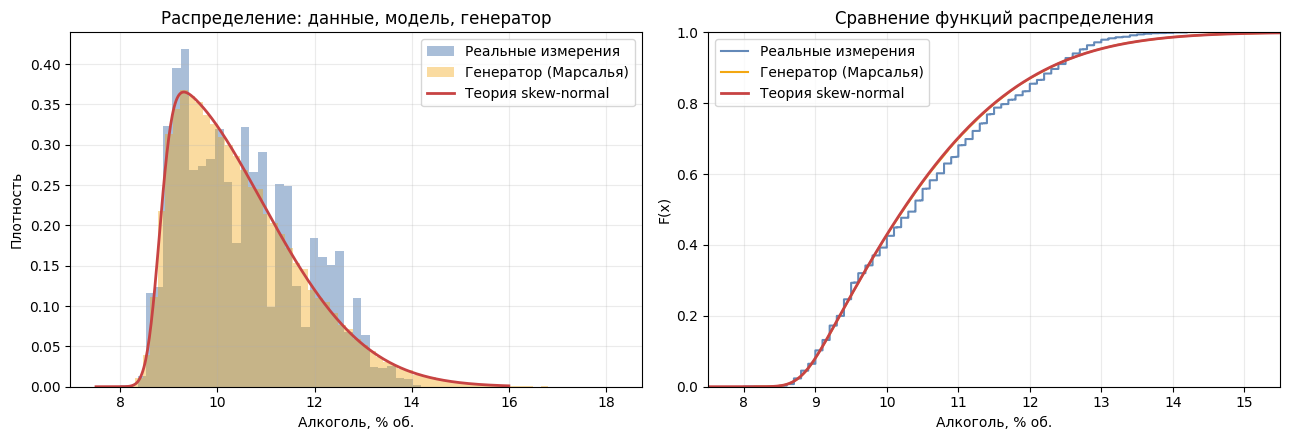

In [32]:
# График 1: гистограмма и плотность выбранной модели
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
x_grid = np.linspace(7.5, 16.0, 450)
axes[0].hist(alcohol_real, bins=35, density=True, alpha=.55,
             color="#6389B8", label="Реальные измерения")
axes[0].hist(alcohol_polar, bins=65, density=True, alpha=.40,
             color="#F3A712", label="Генератор (Марсалья)")
axes[0].plot(x_grid, alcohol_model.pdf(x_grid), color="#C74343", lw=2,
             label="Теория skew-normal")
axes[0].set(xlabel="Алкоголь, % об.", ylabel="Плотность",
            title="Распределение: данные, модель, генератор")
axes[0].legend()

# График 2: эмпирические CDF против теории
def plot_ecdf(ax, values, label, color):
    vals = np.sort(np.asarray(values, dtype=float))
    ax.step(vals, np.arange(1, vals.size + 1) / vals.size,
            where="post", label=label, color=color, lw=1.5)
plot_ecdf(axes[1], alcohol_real, "Реальные измерения", "#6389B8")
plot_ecdf(axes[1], alcohol_polar, "Генератор (Марсалья)", "#F3A712")
axes[1].plot(x_grid, alcohol_model.cdf(x_grid), color="#C74343", lw=2,
             label="Теория skew-normal")
axes[1].set(xlabel="Алкоголь, % об.", ylabel="F(x)",
            title="Сравнение функций распределения", xlim=(7.5, 15.5), ylim=(0, 1))
axes[1].legend()
for ax in axes: ax.grid(alpha=.25)
plt.tight_layout(); plt.show()


**Вывод.** Модельные генераторы должны совпадать по моментам и форме **с теоретическим скошенным нормальным распределением**. При сравнении с исходной таблицей ожидается заметная разница: в спринте 1 сама подогнанная модель имела KS D $\approx0{,}0569$ относительно данных и не воспроизводила отдельные пики. Это **ограничение выбранного распределения, а не доказательство ошибки алгоритма**. Эмпирический генератор, наоборот, сохраняет частоты записанных значений и потому лучше подходит для точного воспроизведения исходной таблицы.


#### 3. Альтернативный метод и частоты округлённых значений


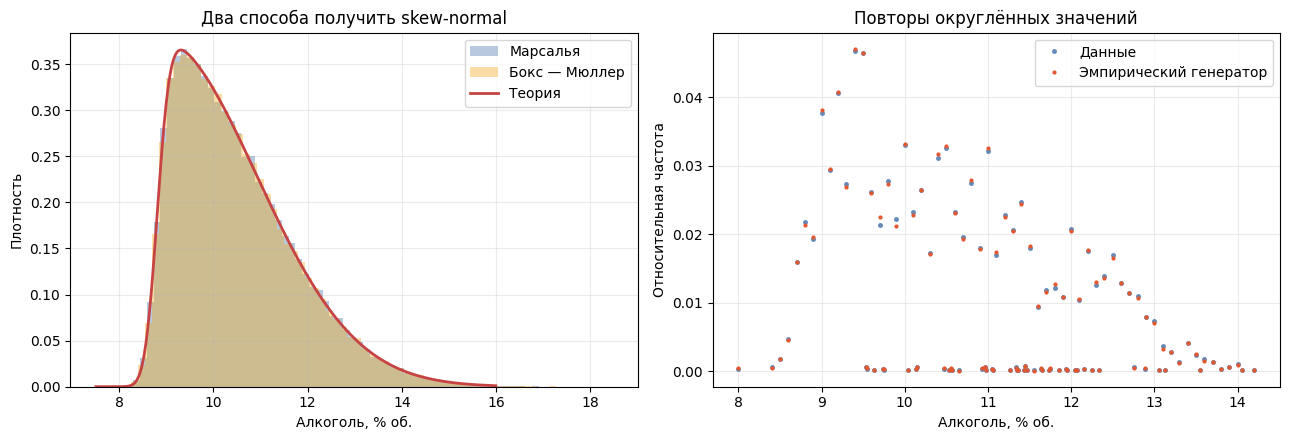

Число различных значений: реальные 103 ; эмпирический генератор 103
KS D: полярный vs Бокс–Мюллер = 0.00276


In [33]:
# Сопоставление двух реализаций skew-normal и эмпирического метода
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(alcohol_polar, bins=70, density=True, alpha=.45,
             color="#6389B8", label="Марсалья")
axes[0].hist(alcohol_bm, bins=70, density=True, alpha=.38,
             color="#F3A712", label="Бокс — Мюллер")
axes[0].plot(x_grid, alcohol_model.pdf(x_grid), color="#C74343", lw=2,
             label="Теория")
axes[0].set(xlabel="Алкоголь, % об.", ylabel="Плотность",
            title="Два способа получить skew-normal")
axes[0].legend()

observed_counts = pd.Series(alcohol_real).value_counts(normalize=True).sort_index()
generated_counts = pd.Series(alcohol_emp).value_counts(normalize=True).sort_index()
axes[1].plot(observed_counts.index, observed_counts.values, ".", ms=5,
             color="#6389B8", label="Данные")
axes[1].plot(generated_counts.index, generated_counts.values, ".", ms=4,
             color="#E4572E", label="Эмпирический генератор")
axes[1].set(xlabel="Алкоголь, % об.", ylabel="Относительная частота",
            title="Повторы округлённых значений")
axes[1].legend()
for ax in axes: ax.grid(alpha=.25)
plt.tight_layout(); plt.show()

print("Число различных значений: реальные", len(observed_counts),
      "; эмпирический генератор", len(generated_counts))
print("KS D: полярный vs Бокс–Мюллер =",
      round(stats.ks_2samp(alcohol_polar, alcohol_bm).statistic, 5))


**Вывод.** Полярный метод и метод Бокса — Мюллера имеют один целевой непрерывный закон, поэтому гистограммы практически совпадают с теоретической плотностью. Эмпирический метод вместо сглаженной кривой воспроизводит **доли округлённых значений**, наблюдаемых в таблице. Для новых непрерывных значений подходит skew-normal, для имитации именно имеющейся таблицы — эмпирический закон.


#### 4. Квантильное преобразование к стандартному нормальному


,сгенерированные,реальные
среднее,0.00436,0.02564
std,1.00009,0.99274
асимметрия,-0.00513,-0.26917
эксцесс,-0.01382,-0.37751
"KS D к N(0,1)",0.00357,0.05687


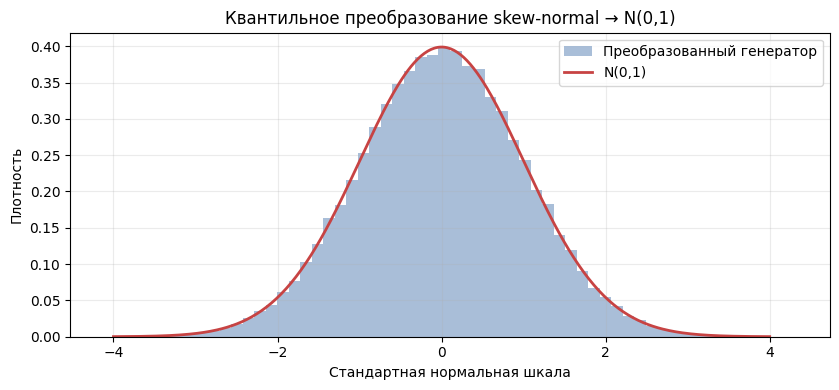

In [34]:
# PIT: применяем ФР skew-normal и обратную ФР нормального распределения.
# Для генератора это должно давать N(0,1); для реальных данных — не обязательно.
z_generated = to_standard_normal(alcohol_polar)
z_real = to_standard_normal(alcohol_real)
normal_check = pd.DataFrame({
    "сгенерированные": [z_generated.mean(), z_generated.std(ddof=1),
                       stats.skew(z_generated), stats.kurtosis(z_generated),
                       stats.kstest(z_generated, stats.norm.cdf).statistic],
    "реальные": [z_real.mean(), z_real.std(ddof=1),
                 stats.skew(z_real), stats.kurtosis(z_real),
                 stats.kstest(z_real, stats.norm.cdf).statistic],
}, index=["среднее", "std", "асимметрия", "эксцесс", "KS D к N(0,1)"])
display(normal_check.round(5))

fig, ax = plt.subplots(figsize=(8.5, 4))
ax.hist(z_generated, bins=60, density=True, alpha=.55, color="#6389B8",
        label="Преобразованный генератор")
zz = np.linspace(-4, 4, 400)
ax.plot(zz, stats.norm.pdf(zz), lw=2, color="#C74343", label="N(0,1)")
ax.set(xlabel="Стандартная нормальная шкала", ylabel="Плотность",
       title="Квантильное преобразование skew-normal → N(0,1)")
ax.legend(); ax.grid(alpha=.25)
plt.tight_layout(); plt.show()


**Вывод.** Для сгенерированного из заданной непрерывной модели $X$ преобразование $\Phi^{-1}(F_{SN}(X))$ восстанавливает стандартное нормальное распределение. Для исходной таблицы результат может отличаться от $N(0,1)$ из-за отклонения реальной формы от модели и повторяющихся округлённых значений. В отличие от простой $z$-стандартизации, здесь используется **вся функция распределения**, а не только среднее и дисперсия.


#### 5. Сравнение скорости и качества трёх методов


In [35]:
import time
bench_rows = []
for title, method in [("Марсалья → skew-normal", "polar"),
                      ("Бокс–Мюллер → skew-normal", "box_muller"),
                      ("Эмпирическая обратная CDF", "empirical")]:
    elapsed = []
    values = None
    for _ in range(3):
        t0 = time.perf_counter()
        values = alcohol_generator(100_000, seed=314, method=method,
                                   data=alcohol_real if method == "empirical" else None)
        elapsed.append(time.perf_counter() - t0)
    ks_target = (stats.ks_2samp(values, alcohol_real).statistic if method == "empirical"
                 else stats.kstest(values, alcohol_model.cdf).statistic)
    bench_rows.append({"метод": title,
                       "время, с (медиана 3 запусков)": np.median(elapsed),
                       "среднее": values.mean(), "std": values.std(ddof=1),
                       "KS D к своему закону": ks_target})
display(pd.DataFrame(bench_rows).round(5))
print("Для двух skew-normal методов цель — теоретическая SN; для эмпирического — исходная таблица.")


,метод,"время, с (медиана 3 запусков)",среднее,std,KS D к своему закону
0,Марсалья → skew-normal,0.01732,10.48165,1.28284,0.00258
1,Бокс–Мюллер → skew-normal,0.01455,10.46979,1.27341,0.00411
2,Эмпирическая обратная CDF,0.01256,10.51944,1.22990,0.00302


Для двух skew-normal методов цель — теоретическая SN; для эмпирического — исходная таблица.


**Вывод.** Время сравнивается на одинаковом числе значений и фиксированном `seed`, а каждый метод оценивается относительно **собственной цели**: скошенного нормального или эмпирического закона. Более быстрое выполнение само по себе не означает более точного воспроизведения исходных данных. Реальная скорость зависит от версии Python, NumPy, SciPy и нагрузки на вычислительную среду.


#### 6. Автотесты генератора


In [36]:
%%writefile tests/test_alcohol.py
import numpy as np
import pytest
from scipy import stats
from winegen.alcohol import (
    alcohol_generator, polar_normal, box_muller_normal,
    to_standard_normal, ALCOHOL_SHAPE, ALCOHOL_LOC, ALCOHOL_SCALE,
)

DATA = np.array([8.7, 9.5, 9.5, 10.0, 10.0, 10.0, 11.7, 12.2])
MODEL = stats.skewnorm(ALCOHOL_SHAPE, loc=ALCOHOL_LOC, scale=ALCOHOL_SCALE)

@pytest.mark.parametrize("method", ["polar", "box_muller", "empirical"])
def test_length_and_zero(method):
    assert alcohol_generator(100, method=method, data=DATA).size == 100
    assert alcohol_generator(0, method=method, data=DATA).size == 0

@pytest.mark.parametrize("method", ["polar", "box_muller", "empirical"])
def test_seed_reproducibility(method):
    a = alcohol_generator(300, seed=12, method=method, data=DATA)
    b = alcohol_generator(300, seed=12, method=method, data=DATA)
    assert np.array_equal(a, b)

@pytest.mark.parametrize("bad_n", [-1, 2.5, "10", True])
def test_invalid_n(bad_n):
    with pytest.raises((TypeError, ValueError)):
        alcohol_generator(bad_n)

def test_invalid_method():
    with pytest.raises(ValueError):
        alcohol_generator(10, method="no_method")

def test_empirical_requires_data():
    with pytest.raises(ValueError):
        alcohol_generator(10, method="empirical")

@pytest.mark.parametrize("bad_data", [[], [1.0, np.nan], [np.inf]])
def test_invalid_empirical_data(bad_data):
    with pytest.raises(ValueError):
        alcohol_generator(10, method="empirical", data=bad_data)

@pytest.mark.parametrize("method", ["polar", "box_muller"])
def test_standard_normal(method):
    rng = np.random.RandomState(7)
    z = polar_normal(75_000, rng) if method == "polar" else box_muller_normal(75_000, rng)
    assert abs(z.mean()) < 0.02
    assert abs(z.std(ddof=1) - 1) < 0.02
    assert stats.kstest(z, stats.norm.cdf).statistic < 0.012

@pytest.mark.parametrize("method", ["polar", "box_muller"])
def test_skew_normal_against_theory(method):
    x = alcohol_generator(80_000, seed=11, method=method)
    assert np.isfinite(x).all()
    assert abs(x.mean() - MODEL.mean()) < 0.04
    assert abs(x.std(ddof=1) - MODEL.std()) < 0.04
    assert stats.kstest(x, MODEL.cdf).statistic < 0.014

def test_two_methods_similar():
    a = alcohol_generator(60_000, seed=1, method="polar")
    b = alcohol_generator(60_000, seed=1, method="box_muller")
    assert stats.ks_2samp(a, b).statistic < 0.02

def test_empirical_support_and_weights():
    x = alcohol_generator(40_000, seed=17, method="empirical", data=DATA)
    assert np.isin(x, DATA).all()
    assert abs(np.mean(x == 10.0) - 3 / 8) < 0.015
    assert stats.ks_2samp(x, DATA).statistic < 0.02

def test_normal_quantile_transform():
    x = alcohol_generator(80_000, seed=23)
    z = to_standard_normal(x)
    assert abs(z.mean()) < 0.02
    assert abs(z.std(ddof=1) - 1) < 0.02
    assert stats.kstest(z, stats.norm.cdf).statistic < 0.014


Writing tests/test_alcohol.py


In [37]:
# Тестируем только свою часть; тесты pH и sugar остаются нетронутыми.
!python -m pytest -q tests/test_alcohol.py


......................                                                   [100%]
22 passed in 3.77s


**Вывод по автотестам.** Проверяются корректная длина результата, нулевое и неверное $n$, обработка недопустимых данных, повторяемость по `seed`, нормальность промежуточного источника, соответствие двум теоретическим распределениям, близость полярного метода и Бокса — Мюллера, эмпирические частоты и квантильное приведение к $N(0,1)$. Численные критерии заданы с допуском на конечную выборку, а тесты воспроизводимы.


### Resume


**Результат.** Для случайной величины `alcohol` реализован собственный генератор скошенного нормального распределения на основе стохастического представления $X=\xi+\omega(\delta|U|+\sqrt{1-\delta^2}V)$. Нормальные величины $U,V$ получены двумя независимыми алгоритмами: полярным методом Марсальи и методом Бокса — Мюллера. Источником равномерных чисел служит MT19937, что обеспечивает воспроизводимость при фиксированном `seed`.

**Точность.** Сравнение с теорией через моменты, квантили, графики плотности и CDF, а также расстояние KS позволяет отделить **правильность самого генератора** от **качества подгонки модели**. Скошенно-нормальное распределение лучше остальных проверенных кандидатов в спринте 1, но не повторяет пики и частоты округлённых измерений полностью.

**Альтернативный вариант.** Дополнительно реализовано обратное эмпирическое квантильное преобразование. Оно сохраняет исходные значения и близкие к исходным частоты, но не генерирует непрерывные новые уровни содержания спирта. Для табличной имитации лучше оно; для гладкого статистического моделирования — скошенно-нормальный вариант.

**Приведение к $N(0,1)$.** Показано, что для непрерывной модели используется $\Phi^{-1}(F_{SN}(X))$, а не просто вычитание среднего и деление на стандартное отклонение.

**Ограничение.** Реальная связь алкоголя и остаточного сахара отрицательная ($r\approx-0{,}45$ в спринте 1). Независимая генерация трёх показателей не сохранит эти зависимости: для совместной генерации необходима многомерная модель.


## Исследование алгоритмов датчиков (доп. баллы) — alcohol


| Алгоритм | Распределение и механизм | Применение | Преимущества | Ограничения | Реализация |
|---|---|---|---|---|---|
| Вихрь Мерсенна MT19937 | псевдослучайные $U(0,1)$ | исходный источник для моделирования | воспроизводимость, большой период | не криптографический | `np.random.RandomState` |
| Полярный метод Марсальи | $U(-1,1)^2\to N(0,1)$, отбор внутри круга | нормальные числа в моделировании | нет `sin` и `cos`, два нормальных значения за принятую пару | часть кандидатов отбрасывается | `polar_normal` |
| Бокс — Мюллер | $U(0,1)^2\to N(0,1)^2$ | эталонное преобразование для нормальных величин | точная аналитическая формула, без отбрасывания | используются `sin`, `cos`, `log` | `box_muller_normal` |
| Стохастическое представление skew-normal | $\delta|U|+\sqrt{1-\delta^2}V$ | моделирование асимметричных величин | простая формула через нормальные величины | модель может не отражать локальные пики данных | `skew_normal_latent` |
| Обратная эмпирическая CDF | $U\to\widehat F^{-1}(U)$ | бутстрэп, имитация частот наблюдений | воспроизводит значения и частоты таблицы | нет новых промежуточных значений | `empirical_inverse` |
| Квантильное преобразование | $\Phi^{-1}(F_{SN}(x))$ | приведение непрерывной модели к $N(0,1)$ | использует полную форму распределения | требует достаточно точного $F_{SN}$ | `to_standard_normal` |

Скорость и точность трёх непосредственно реализованных генераторов сравниваются в разделе **Tests**. Для эмпирического и для непрерывного вариантов используются разные целевые распределения.


## Литература — alcohol

1. Cortez P., Cerdeira A., Almeida F., Matos T., Reis J. *Wine Quality* [Dataset]. UCI Machine Learning Repository, 2009. https://doi.org/10.24432/C56S3T
2. Azzalini A. A class of distributions which includes the normal ones // *Scandinavian Journal of Statistics*. 1985. Vol. 12, No. 2. P. 171–178.
3. Azzalini A., Capitanio A. Statistical applications of the multivariate skew-normal distribution // *Journal of the Royal Statistical Society B*. 1999. Vol. 61. P. 579–602. https://arxiv.org/abs/0911.2093
4. Marsaglia G., Bray T. A convenient method for generating normal variables // *SIAM Review*. 1964. Vol. 6, No. 3. P. 260–264.
5. Box G. E. P., Muller M. E. A note on the generation of random normal deviates // *The Annals of Mathematical Statistics*. 1958. Vol. 29, No. 2. P. 610–611. https://doi.org/10.1214/aoms/1177706645
6. Matsumoto M., Nishimura T. Mersenne Twister: A 623-dimensionally equidistributed uniform pseudo-random number generator // *ACM Transactions on Modeling and Computer Simulation*. 1998. Vol. 8, No. 1. P. 3–30.
7. Devroye L. *Non-Uniform Random Variate Generation*. Springer, 1986. https://luc.devroye.org/rnbookindex.html
8. SciPy documentation: `scipy.stats.skewnorm`. https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.skewnorm.html
9. NumPy documentation: `numpy.random.RandomState` (MT19937). https://numpy.org/doc/stable/reference/random/legacy.html


## Lab resume — sprint 2 (общее)


### Итоговая проверка автотестов всех генераторов

In [38]:
!python -m pytest -q tests

.................................................................        [100%]
65 passed in 3.39s


Три генератора охватывают разные свойства исходных измерений. Для **pH** реализовано сдвинутое лог-нормальное распределение, для **residual sugar** — эмпирическое распределение и гамма-модель, для **alcohol** — скошенное нормальное и эмпирический закон. Проверки включают математическое описание алгоритмов, сравнение характеристик с целевыми распределениями, визуализации и автоматические тесты.

**Ключевое ограничение.** Проверяется качество отдельных **маргинальных** распределений. При независимой генерации pH, сахара и алкоголя не сохраняются эмпирические корреляции между признаками: для полноценного искусственного набора вин потребуется совместная модель.

**Проверяемость.** Код разделён на `winegen/ph.py`, `winegen/sugar.py`, `winegen/alcohol.py`; тесты — на `tests/test_ph.py`, `tests/test_sugar.py`, `tests/test_alcohol.py`. Все файлы создаются соответствующими ячейками `%%writefile` при последовательном запуске ноутбука.


### cat_mark_table — sprint 2


| cat_id | notebook_link | coeff | comment |
|---|---|---:|---|
| Алгоритм генератора и математика | [pH](#scrollTo=YdLqs4sSZYju) · [sugar](#scrollTo=19f0e692) · [alcohol](#scrollTo=dbc54b98f8) | 1 | три типа распределений; собственные преобразования из MT19937 |
| Проверка соответствия генератора теории | [Тесты pH](#scrollTo=WhR2AwbvZlGD) · [sugar](#scrollTo=9fc9bd51) · [alcohol](#scrollTo=1101d7b2fb) | 1 | моменты, квантили, KS, графики |
| Сравнение с реальными данными | [Графики и метрики](#scrollTo=1101d7b2fb) | 1 | статистики, визуализации, ограничения моделей |
| Альтернативные алгоритмы | [Альтернативные методы](#scrollTo=a9a88985d4) | 1 | полярный метод, отношения, Бокс—Мюллер, квантильный, Нейман |
| Математическое обоснование | [Математика](#scrollTo=fe2db26b6e) | 1 | плотности, стохастические представления, преобразования |
| Литература и методы | [Источники](#scrollTo=b18f427b27) | 1 | книги, статьи, документация |
| Автотесты генераторов | [Автотесты](#scrollTo=9c15f051f3) | 1 | параметры, воспроизводимость, соответствие законам |
| Табличные итоговые метрики | [Таблицы](#scrollTo=1101d7b2fb) | 1 | описательные статистики, статистики KS, бенчмарки |

Значения `coeff` в таблице — заявленные выполненные категории; фактическое оценивание остаётся за преподавателем.
